# Projeto A3 — Microestrutura do Bitcoin (BTC/USDT) em uma semana de estresse

**Análise de Dados e Big Data (0005073)** · **Checkpoint 2 — Auditoria & ETL + EDA inicial**

**Grupo:** _[Gabriel Almeida Portela — 825233281]_ · _[Daniel Almeida Portela — 825234443]_

**Base:** [Bitcoin (BTC/USDT) Tick-Level Trade Data — Free Sample](https://huggingface.co/datasets/jalvart/bitcoin-tick-level-trade-data-free-sample) (27,9 milhões de negócios, 9 colunas, 19–25/02/2025)
**Fonte primária usada para validação:** [Binance Public Data](https://data.binance.vision)

---

### Roteiro

| # | Seção | O que entrega |
|---|---|---|
| 0 | Contexto e perguntas de negócio | Resumo do Checkpoint 1 |
| 1 | Configuração do ambiente | Bibliotecas, parâmetros, estilo dos gráficos |
| 2 | **Extração** | Download com verificação de integridade (SHA-256) |
| 3 | **Auditoria de qualidade** | Completude, unicidade, validade, consistência e outliers do dado bruto |
| 4 | **Transformação (limpeza)** | Tipos, nulos, duplicatas, colunas inúteis, novas variáveis, contrato de qualidade |
| 5 | **Validação cruzada** | Reconciliação minuto a minuto com os candles oficiais da Binance |
| 6 | **Carga e agregações** | Barras de 1 min e 1 s (com tratamento de lacunas), ordens agressoras, arquivos Parquet |
| 7 | **EDA inicial** | Estatística descritiva, distribuições, `groupby`, séries temporais, correlações |
| 8 | Respostas preliminares | P1, P2 e P3 com números |
| 9 | Próximos passos | O que fica para o Checkpoint 3 |

> **Como executar.** No Google Colab: *Arquivo → Fazer upload de notebook* e depois *Ambiente de execução → Executar tudo*. O notebook baixa os dados sozinho (≈ 100 MB). Localmente, rode a partir da pasta `notebooks/` com o ambiente do `requirements.txt`. Tempo total ≈ 1–3 min. Pico de RAM ≈ 6 GB com pandas 3 e ≈ 9 GB com pandas 2.2, o que cabe no Colab gratuito (≈ 12 GB).

## 0. Contexto e perguntas de negócio

**Cenário.** Somos o time de dados de uma **mesa de execução de criptoativos**, a área que recebe ordens grandes de clientes institucionais e precisa executá-las no mercado à vista de **BTC/USDT da Binance**. Uma ordem grande colocada na hora errada consome várias faixas de preço do livro (*slippage*) e fica exposta a movimentos bruscos.

**Período.** De 19 a 25/02/2025, uma semana de estresse: em 21/02 a corretora Bybit sofreu o maior roubo de criptoativos já registrado (≈ US$ 1,5 bi em ETH), e o bitcoin saiu de US$ 99,5 mil para US$ 86 mil até 25/02.

| | Pergunta | Decisão que apoia |
|---|---|---|
| **P1** | Em quais **horários (UTC)** o BTC/USDT concentra maior volume e número de negócios, e como a **volatilidade** acompanha essa liquidez? | Janela para executar ou fatiar ordens grandes |
| **P2** | Como volume, volatilidade e **perfil de tamanho dos negócios** mudaram nos **dias de estresse** em comparação com os demais? Quem concentra o volume? | Limites de risco, alertas, capacidade operacional |
| **P3** | O **desequilíbrio entre compras e vendas agressoras (OFI)** está associado ao retorno no mesmo minuto? Ele **antecipa** o minuto seguinte? | Viabilidade de um sinal/modelo preditivo (CP3) |

O dicionário de dados completo está em `CHECKPOINT_1.md`. O dicionário da base **tratada** é gerado ao final da seção 6.

## 1. Configuração do ambiente

Todas as bibliotecas abaixo já vêm instaladas no Google Colab. Usamos **pandas** para manipulação, **pyarrow** para ler Parquet, **matplotlib/seaborn** para gráficos e só a biblioteca padrão do Python para downloads e hashes.

In [3]:
# --- Bibliotecas ---------------------------------------------------------------
import gc                      # coleta de lixo: libera memória após apagar DataFrames grandes
import hashlib                 # SHA-256 para verificar a integridade dos arquivos baixados
import shutil
import time
import urllib.request          # download sem dependências externas
import zipfile
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import seaborn as sns
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# Economia de memória (a base tem 27,9 mi de linhas e o Colab gratuito, ~12 GB de RAM):
# 1) textos guardados em formato Arrow (compacto). É o padrão no pandas 3; no 2.x é ativado aqui,
#    o que deixa o notebook com o mesmo comportamento nas duas versões;
# 2) o Arrow passa a usar o alocador do sistema, que devolve a memória liberada ao sistema
#    operacional (o alocador padrão a retém, e o uso de RAM ficaria ~2 GB maior).
if int(pd.__version__.split(".")[0]) < 3:
    pd.set_option("future.infer_string", True)
pa.set_memory_pool(pa.system_memory_pool())

print(f"pandas {pd.__version__} | numpy {np.__version__} | pyarrow {pa.__version__} | seaborn {sns.__version__}")

pandas 3.1.1 | numpy 2.5.5 | pyarrow 26.0.1 | seaborn 0.13.2


In [4]:
# --- Parâmetros do projeto -----------------------------------------------------
# Fixamos o commit do repositório e o hash do arquivo: assim qualquer pessoa que
# rodar o notebook analisa EXATAMENTE os mesmos bytes (reprodutibilidade).
HF_REPO = "jalvart/bitcoin-tick-level-trade-data-free-sample"
HF_REVISION = "c90f6087f5975daec7fe80e6ed110dd19108bd5c"
FILE_NAME = "sample_BTC_2025-02-19_to_2025-02-26.parquet"
DATA_URL = f"https://huggingface.co/datasets/{HF_REPO}/resolve/{HF_REVISION}/data/{FILE_NAME}"
EXPECTED_SHA256 = "2a6602489e57e8fcde945e082eba0a60ea95484ee8cfe3333ea1fe166d44070a"

# Data da última publicação do arquivo no Hugging Face. Nenhum registro pode ter
# sido "ingerido" depois disso (usado para validar a coluna ingest_ts).
DATASET_PUBLISHED_AT = pd.Timestamp("2026-10-25 10:12:10", tz="UTC")

# Período declarado pelo fornecedor (nome do arquivo / README).
PERIOD_START = pd.Timestamp("2025-02-19", tz="UTC")
PERIOD_END_DECLARED = pd.Timestamp("2025-02-26", tz="UTC")

# Candles oficiais de 1 minuto da Binance (fonte primária) para validação cruzada.
BINANCE_KLINES_URL = "https://data.binance.vision/data/spot/daily/klines/BTCUSDT/1m"

# Regra objetiva (e não "escolha a dedo") para classificar um dia como de estresse:
# amplitude intradiária (máxima/mínima − 1) acima de 4 %.
STRESS_RANGE_THRESHOLD = 0.04

# --- Pastas --------------------------------------------------------------------
# Funciona no Colab (/content) e localmente (rodando de dentro de notebooks/).
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = BASE_DIR / "data" / "raw"              # dado bruto, nunca alterado
EXT_DIR = BASE_DIR / "data" / "external"         # fonte externa (Binance)
PROC_DIR = BASE_DIR / "data" / "processed"       # saídas do ETL
for folder in (RAW_DIR, EXT_DIR, PROC_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("Diretório base:", BASE_DIR)

Diretório base: c:\Users\User\Downloads\projects\btc-data-analysis


In [5]:
# --- Formatação no padrão brasileiro ---------------------------------------------
def br(x, nd=0):
    # 1234567.891 -> "1.234.567,89"
    s = f"{x:,.{nd}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")


def br_pct(frac, nd=1):
    # 0.4172 -> "41,7 %"
    return f"{br(frac * 100, nd)} %"


def br_auto(x):
    # Inteiros com milhar; decimais com até 5 casas, sem zeros à direita
    if isinstance(x, (bool, np.bool_)) or not isinstance(x, (int, float, np.integer, np.floating)):
        return x
    if float(x).is_integer():
        return br(x)
    return br(x, 5).rstrip("0").rstrip(",")


def styled(df, nd=2):
    # Exibe tabelas com separador de milhar "." e decimal ","
    return df.style.format(precision=nd, thousands=".", decimal=",", na_rep="—")


DIAS_PT = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]


def day_label(ts):
    return f"{DIAS_PT[ts.day_of_week]} {ts:%d/%m}"


# --- Estilo dos gráficos ----------------------------------------------------------
# Paleta categórica validada para daltonismo (protanopia/deuteranopia/tritanopia) e
# contraste. As cores têm FUNÇÃO fixa em todo o notebook:
#   azul = compra / série principal · laranja = venda · cinza = contexto/sem destaque
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, NEUTRAL = "#e1e0d9", "#c3c2b7", "#f0efec"
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
COLOR_SIDE = {"buy": BLUE, "sell": ORANGE}
LABEL_SIDE = {"buy": "compra", "sell": "venda"}
SEQ_CMAP = LinearSegmentedColormap.from_list(
    "seq_azul", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV_CMAP = LinearSegmentedColormap.from_list("div_verm_azul", [RED, NEUTRAL, BLUE])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "figure.figsize": (11, 4.2), "figure.constrained_layout.use": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titlecolor": INK_2, "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", RED]),
    "timezone": "UTC",
    "text.parse_math": False,   # "US$" não deve ser lido como fórmula LaTeX
})

FMT_BR = mticker.FuncFormatter(lambda v, _: br(v))
FMT_BR_1 = mticker.FuncFormatter(lambda v, _: br(v, 1))
FMT_BR_2 = mticker.FuncFormatter(lambda v, _: br(v, 2))
# Eixos em escala log: 1; 0,1; 0,01... (sem notação científica)
FMT_LOG = mticker.FuncFormatter(lambda v, _: br(v, max(0, -int(np.floor(np.log10(v))))) if v > 0 else "")


def log_axis(axis):
    axis.set_major_formatter(FMT_LOG)
    axis.set_minor_formatter(mticker.NullFormatter())


def headline(fig, text):
    # Título-manchete do gráfico: diz a CONCLUSÃO, não só o assunto.
    fig.suptitle(text, x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)


# --- Registro de achados da auditoria ----------------------------------------------
# Cada problema encontrado vira uma linha deste log -> relatório consolidado no fim.
AUDIT_LOG = []


def log_issue(dimension, column, finding, evidence, severity, action):
    AUDIT_LOG.append({"dimensão": dimension, "coluna": column, "achado": finding,
                      "evidência": evidence, "severidade": severity, "tratamento": action})

## 2. Extração (E)

O arquivo é baixado da fonte e **conferido por SHA-256**. Se um único byte estiver diferente (download corrompido, arquivo alterado pelo fornecedor), o notebook para em vez de analisar dados errados. É o primeiro filtro contra *Garbage In*.

In [6]:
def sha256_of(path, chunk_size=1 << 20):
    # Lê o arquivo em blocos de 1 MB para não carregar tudo na memória
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def download(url, dest, expected_sha256=None):
    # Baixa `url` para `dest` (só se ainda não existir) e confere o hash.
    dest = Path(dest)
    if not dest.exists():
        t0 = time.time()
        tmp = dest.with_name(dest.name + ".part")   # evita deixar arquivo pela metade
        with urllib.request.urlopen(url, timeout=300) as resp, open(tmp, "wb") as out:
            shutil.copyfileobj(resp, out)
        tmp.replace(dest)
        print(f"Baixado {dest.name}: {br(dest.stat().st_size / 1e6, 1)} MB em {br(time.time() - t0, 1)} s")
    if expected_sha256 is not None:
        digest = sha256_of(dest)
        if digest != expected_sha256:
            dest.unlink()
            raise ValueError(f"SHA-256 divergente em {dest.name}: {digest} != {expected_sha256}")
    return dest


RAW_PATH = download(DATA_URL, RAW_DIR / FILE_NAME, EXPECTED_SHA256)
print(f"Integridade confirmada: {RAW_PATH.name} | SHA-256 {EXPECTED_SHA256[:16]}…")

Baixado sample_BTC_2025-02-19_to_2025-02-26.parquet: 103,4 MB em 16,9 s
Integridade confirmada: sample_BTC_2025-02-19_to_2025-02-26.parquet | SHA-256 2a6602489e57e8fc…


### 2.1 Metadados do Parquet (antes de carregar)

O Parquet guarda o esquema (nomes, tipos e se a coluna aceita nulo). Ler os metadados primeiro é barato e já mostra o que esperar.

In [7]:
pf = pq.ParquetFile(RAW_PATH)
meta = pf.metadata
print(f"Linhas: {br(meta.num_rows)} | Colunas: {meta.num_columns} | Row groups: {meta.num_row_groups} "
      f"| Compressão: {meta.row_group(0).column(0).compression}")

schema_tbl = pd.DataFrame(
    [{"coluna": f.name, "tipo no arquivo (Arrow)": str(f.type), "aceita nulo?": "sim" if f.nullable else "não"}
     for f in pf.schema_arrow]
).set_index("coluna")
display(schema_tbl)

Linhas: 27.925.338 | Colunas: 9 | Row groups: 29 | Compressão: ZSTD


,tipo no arquivo (Arrow),aceita nulo?
coluna,,
exchange,"dictionary<values=string, indices=int8, ordere...",não
symbol,"dictionary<values=string, indices=int8, ordere...",não
trade_id,string,não
exchange_ts,int64,não
ingest_ts,int64,não
price,double,não
quantity,double,não
aggressor_side,int8,não
raw_side,string,sim


O esquema já mostra dois sinais de alerta. `trade_id` está como **texto** (`string`), embora seja um número sequencial, e os dois timestamps estão como **inteiros** (`int64`), não como data-hora. `raw_side` é a única coluna que aceita nulo.

In [8]:
t0 = time.time()
df_raw = pd.read_parquet(RAW_PATH)
pa.default_memory_pool().release_unused()   # devolve ao sistema a memória temporária da leitura
print(f"Carregado em {br(time.time() - t0, 1)} s -> {br(len(df_raw))} linhas x {df_raw.shape[1]} colunas | "
      f"memória: {br(df_raw.memory_usage(deep=True).sum() / 1e9, 2)} GB")
display(df_raw.head(10))

Carregado em 17,3 s -> 27.925.338 linhas x 9 colunas | memória: 1,80 GB


,exchange,symbol,trade_id,exchange_ts,ingest_ts,price,quantity,aggressor_side,raw_side
0,binance,BTCUSDT,4570646084,1739923200219,1964796000000,95671.74,0.00185,-1,sell
1,binance,BTCUSDT,4570646085,1739923200270,1964796000000,95671.75,0.00006,1,buy
2,binance,BTCUSDT,4570646086,1739923200270,1964796000000,95671.75,0.00006,1,buy
3,binance,BTCUSDT,4570646087,1739923200270,1964796000000,95671.75,0.00006,1,buy
4,binance,BTCUSDT,4570646088,1739923200270,1964796000000,95671.75,0.00006,1,buy
5,binance,BTCUSDT,4570646089,1739923200270,1964796000000,95671.75,0.00006,1,buy
6,binance,BTCUSDT,4570646090,1739923200270,1964796000000,95671.75,0.00006,1,buy
7,binance,BTCUSDT,4570646091,1739923200270,1964796000000,95671.75,0.00006,1,buy
8,binance,BTCUSDT,4570646092,1739923200270,1964796000000,95671.75,0.00006,1,buy
9,binance,BTCUSDT,4570646093,1739923200270,1964796000000,95671.75,0.00006,1,buy


Nas primeiras 10 linhas: `ingest_ts` = 1.964.796.000.000 ms equivale a **abril de 2032**, e as linhas 1 a 9 são idênticas em tudo menos o `trade_id`. Os dois pontos são investigados na auditoria.

## 3. Auditoria de qualidade (dado bruto)

A auditoria segue as **dimensões clássicas de qualidade de dados**:

| Dimensão | Pergunta |
|---|---|
| **Completude** | Falta algum valor ou algum registro? |
| **Unicidade** | Há registros repetidos? |
| **Validade** | Os valores respeitam tipo, domínio e regras de negócio? |
| **Consistência** | As colunas concordam entre si e com os metadados? |
| **Exatidão / outliers** | Há valores extremos? São erro ou realidade? |

Nada é alterado nesta seção, só medido. Cada achado é registrado em `AUDIT_LOG`.

### 3.1 Perfil geral das colunas

In [9]:
def profile(df):
    # Uma linha por coluna: tipo, nulos, cardinalidade, mínimo e máximo
    rows = []
    for col in df.columns:
        s = df[col]
        numeric = pd.api.types.is_numeric_dtype(s) and not isinstance(s.dtype, pd.CategoricalDtype)
        rows.append({
            "coluna": col,
            "dtype pandas": str(s.dtype),
            "nulos": int(s.isna().sum()),
            "% nulos": s.isna().mean() * 100,
            "valores distintos": int(s.nunique()),
            "mínimo": br_auto(s.min()) if numeric else "—",
            "máximo": br_auto(s.max()) if numeric else "—",
            "exemplo": str(s.iloc[0]),
        })
    return pd.DataFrame(rows).set_index("coluna")


raw_profile = profile(df_raw)
styled(raw_profile, nd=1)

,dtype pandas,nulos,% nulos,valores distintos,mínimo,máximo,exemplo
coluna,,,,,,,
exchange,category,0,"0,0",1,—,—,binance
symbol,category,0,"0,0",1,—,—,BTCUSDT
trade_id,str,0,"0,0",27.925.338,—,—,4570646084
exchange_ts,int64,0,"0,0",4.531.161,1.739.923.200.219,1.740.527.999.694,1739923200219
ingest_ts,int64,0,"0,0",7,1.964.796.000.000,2.115.156.000.000,1964796000000
price,float64,0,"0,0",1.108.754,"86.050,99",99.475,95671.74
quantity,float64,0,"0,0",75.841,"0,00001","56,34875",0.00185
aggressor_side,int8,0,"0,0",2,-1,1,-1
raw_side,str,0,"0,0",2,—,—,sell


### 3.2 Completude

Verificamos três níveis:
1. **nulos explícitos** (`NaN`/`None`);
2. **nulos disfarçados**: textos vazios, `"null"`, `"N/A"`, zeros ou negativos onde não fazem sentido;
3. **registros faltantes**: num fluxo de negócios, um "nulo" é um **negócio que deveria existir e não está no arquivo**. O `trade_id` é sequencial na Binance, então buracos na sequência revelariam perdas.

In [10]:
# (1) Nulos explícitos -----------------------------------------------------------
explicit_nulls = df_raw.isna().sum()

# (2) Nulos disfarçados ----------------------------------------------------------
NULL_TOKENS = {"", "nan", "null", "none", "n/a", "na", "-", "?"}
disguised = {}
for col in ["exchange", "symbol", "raw_side"]:
    s = df_raw[col]
    if isinstance(s.dtype, pd.CategoricalDtype):
        # Coluna categórica: basta olhar as categorias (barato)
        bad_values = [c for c in s.cat.categories if str(c).strip().lower() in NULL_TOKENS]
        disguised[col] = int(s.isin(bad_values).sum())
    else:
        disguised[col] = int(s.str.strip().str.lower().isin(NULL_TOKENS).sum())
for col in ["price", "quantity", "exchange_ts", "ingest_ts"]:
    disguised[col] = int((df_raw[col] <= 0).sum())      # zero/negativo é impossível aqui
disguised["aggressor_side"] = int((df_raw["aggressor_side"] == 0).sum())   # 0 = "lado desconhecido"

# trade_id: em vez de procurar "null"/vazio, exigimos que TODO valor seja só dígitos
n_non_numeric = int((~df_raw["trade_id"].str.fullmatch(r"\d+")).sum())
disguised["trade_id"] = n_non_numeric

# (3) Registros faltantes: buracos na sequência de trade_id --------------------------
assert n_non_numeric == 0, "há trade_id não numérico; tratar antes de converter"
trade_id_num = df_raw["trade_id"].astype("int64")
expected_ids = int(trade_id_num.max() - trade_id_num.min() + 1)
missing_ids = expected_ids - trade_id_num.nunique()
completeness = pd.DataFrame({"nulos explícitos": explicit_nulls,
                             "nulos disfarçados (vazio/'null'/≤ 0/não numérico)": pd.Series(disguised)})
display(styled(completeness, nd=0))
print(f"trade_id não numéricos: {n_non_numeric}")
print(f"IDs esperados (máx - mín + 1): {br(expected_ids)} | IDs presentes: {br(trade_id_num.nunique())} "
      f"| IDs faltantes: {br(missing_ids)}")

# (4) Cobertura temporal: há minutos sem nenhum negócio? ------------------------------
ts_raw = pd.to_datetime(df_raw["exchange_ts"], unit="ms", utc=True)
minutes_expected = int((ts_raw.max().ceil("D") - PERIOD_START) / pd.Timedelta("1min"))
minutes_observed = ts_raw.dt.floor("min").nunique()
print(f"Minutos no período: {br(minutes_expected)} | minutos com negócio: {br(minutes_observed)} "
      f"| maior intervalo entre dois negócios: {ts_raw.diff().max().total_seconds():.1f} s")
print(f"Primeiro negócio: {ts_raw.min()} | último: {ts_raw.max()}")

,nulos explícitos,nulos disfarçados (vazio/'null'/≤ 0/não numérico)
aggressor_side,0,0
exchange,0,0
exchange_ts,0,0
ingest_ts,0,0
price,0,0
quantity,0,0
raw_side,0,0
symbol,0,0
trade_id,0,0


trade_id não numéricos: 0
IDs esperados (máx - mín + 1): 27.925.338 | IDs presentes: 27.925.338 | IDs faltantes: 0
Minutos no período: 10.080 | minutos com negócio: 10.080 | maior intervalo entre dois negócios: 8.2 s
Primeiro negócio: 2025-02-19 00:00:00.219000+00:00 | último: 2025-02-25 23:59:59.694000+00:00


In [11]:
log_issue("Completude", "todas", "Nenhum nulo explícito ou disfarçado",
          f"{int(explicit_nulls.sum())} NaN; {sum(disguised.values())} vazios/'null'/≤ 0", "—",
          "Nenhum (base já higienizada pelo fornecedor)")
log_issue("Completude", "trade_id", "Sequência completa, sem negócios faltantes",
          f"{br(expected_ids)} IDs esperados = {br(trade_id_num.nunique())} presentes", "—", "Nenhum")
log_issue("Consistência", "metadados", "Período declarado ≠ período observado",
          f"Arquivo/README: até 26/02; último negócio: {ts_raw.max():%d/%m %H:%M:%S} UTC", "baixa",
          "Documentar: o período real é 19/02 00:00 a 25/02 23:59:59 UTC (7 dias)")

**Conclusão.** Não há nenhum nulo, nem explícito nem disfarçado, e **nenhum negócio faltante**: os 27.925.338 IDs formam uma sequência contínua, e todos os 10.080 minutos da semana têm negócios. O único problema de completude está nos **metadados**: o arquivo se diz "até 26/02", mas termina em 25/02 23:59:59. A data final do nome é exclusiva, ou seja, 26/02 não está incluído.

### 3.3 Unicidade (duplicatas)

Três testes, do mais estrito ao mais frouxo:
1. linha **inteira** repetida;
2. **chave** repetida (`trade_id`);
3. **duplicata aparente**: linhas iguais em tudo **exceto** o `trade_id`.

In [12]:
n_full_dup = int(df_raw.duplicated().sum())
n_key_dup = int(df_raw["trade_id"].duplicated().sum())
cols_without_id = [c for c in df_raw.columns if c != "trade_id"]
apparent_dup = df_raw.duplicated(subset=cols_without_id, keep="first")

print(f"(1) Linhas inteiras duplicadas: {br(n_full_dup)}")
print(f"(2) trade_id duplicado:         {br(n_key_dup)}")
print(f"(3) Duplicatas aparentes:       {br(apparent_dup.sum())} ({br_pct(apparent_dup.mean())} das linhas)")

(1) Linhas inteiras duplicadas: 0
(2) trade_id duplicado:         0
(3) Duplicatas aparentes:       11.631.537 (41,7 % das linhas)


Os testes 1 e 2 dão zero. O teste 3 marca **41,7 % da base**. Antes de apagar qualquer coisa, olhamos um exemplo:

In [13]:
example_ts = df_raw["exchange_ts"].iloc[1]
display(df_raw[df_raw["exchange_ts"] == example_ts])

,exchange,symbol,trade_id,exchange_ts,ingest_ts,price,quantity,aggressor_side,raw_side
1,binance,BTCUSDT,4570646085,1739923200270,1964796000000,95671.75,0.00006,1,buy
2,binance,BTCUSDT,4570646086,1739923200270,1964796000000,95671.75,0.00006,1,buy
3,binance,BTCUSDT,4570646087,1739923200270,1964796000000,95671.75,0.00006,1,buy
4,binance,BTCUSDT,4570646088,1739923200270,1964796000000,95671.75,0.00006,1,buy
5,binance,BTCUSDT,4570646089,1739923200270,1964796000000,95671.75,0.00006,1,buy
6,binance,BTCUSDT,4570646090,1739923200270,1964796000000,95671.75,0.00006,1,buy
7,binance,BTCUSDT,4570646091,1739923200270,1964796000000,95671.75,0.00006,1,buy
8,binance,BTCUSDT,4570646092,1739923200270,1964796000000,95671.75,0.00006,1,buy
9,binance,BTCUSDT,4570646093,1739923200270,1964796000000,95671.75,0.00006,1,buy
10,binance,BTCUSDT,4570646094,1739923200270,1964796000000,95671.75,0.00006,1,buy


São 9 negócios no **mesmo milissegundo**, com o mesmo preço, a mesma quantidade e o mesmo lado, mas com **IDs consecutivos diferentes**. Isso é o funcionamento normal do motor de negociação. Uma **ordem agressora** (por exemplo, uma compra a mercado) é casada contra várias **ordens passivas** no livro. Cada casamento gera um negócio separado, com ID próprio e o mesmo timestamp. Se 8 robôs deixaram ordens de 0,00006 BTC no mesmo preço, uma compra que consome todas gera 8 linhas "iguais".

O que aconteceria com um `drop_duplicates()` ingênuo:

In [14]:
notional_raw = df_raw["price"] * df_raw["quantity"]
naive_impact = pd.DataFrame({
    "negócios apagados": [int(apparent_dup.sum())],
    "% dos negócios": [apparent_dup.mean() * 100],
    "volume apagado (US$ mi)": [notional_raw[apparent_dup].sum() / 1e6],
    "% do volume US$": [notional_raw[apparent_dup].sum() / notional_raw.sum() * 100],
}, index=["drop_duplicates() ingênuo"])
display(styled(naive_impact, nd=1))

print("Quantidades mais comuns entre as duplicatas aparentes (BTC):")
display(df_raw.loc[apparent_dup, "quantity"].value_counts().head(5).rename("negócios").to_frame())

,negócios apagados,% dos negócios,volume apagado (US$ mi),% do volume US$
drop_duplicates() ingênuo,11.631.537,"41,7","410,5","2,2"


Quantidades mais comuns entre as duplicatas aparentes (BTC):


,negócios
quantity,
0.00006,10156068
0.00007,286956
0.00014,115652
0.00015,105691
0.00009,94183


In [15]:
log_issue("Unicidade", "todas / trade_id", "Sem duplicatas reais", "0 linhas e 0 IDs repetidos", "—",
          "drop_duplicates(subset='trade_id') como proteção idempotente")
log_issue("Unicidade", "todas exceto trade_id", "Duplicatas APARENTES (execuções parciais)",
          f"{br(apparent_dup.sum())} linhas ({br_pct(apparent_dup.mean())}); {br(naive_impact['% do volume US$'].iloc[0], 1)} % do volume",
          "alta (armadilha)", "MANTER; agregar em 'ordens agressoras' (seção 6.3); confirmado pela Binance (seção 5)")

**Decisão: manter.** Apagar essas linhas removeria 41,7 % dos negócios, mas só 2,2 % do volume financeiro. As duplicatas aparentes são, em sua maioria, **negócios minúsculos** (0,00006 BTC ≈ US$ 5,7, perto do valor mínimo de ordem da Binance). A remoção distorceria qualquer métrica de contagem (P1, P2) e o fluxo de ordens (P3). Em vez de apagar, criamos na seção 6 uma tabela de **ordens agressoras** que agrupa as execuções parciais. A seção 5 prova que essas linhas existem na fonte oficial: a contagem de negócios por minuto bate 100 % com a Binance.

### 3.4 Validade (tipos, domínios e regras de negócio)

In [16]:
validity = []

# trade_id: guardado como texto, mas todos os valores são inteiros
mem_str = df_raw["trade_id"].memory_usage(deep=True) / 1e6
mem_int = trade_id_num.memory_usage(deep=True) / 1e6
validity.append(("trade_id", "texto só com dígitos", n_non_numeric == 0,
                 f"tipo inadequado: texto ocupa {br(mem_str)} MB vs {br(mem_int)} MB como int64"))

# exchange_ts: dentro do período declarado?
in_period = ts_raw.between(PERIOD_START, PERIOD_END_DECLARED, inclusive="left").all()
validity.append(("exchange_ts", "dentro de [19/02, 26/02)", bool(in_period), "inteiro em ms -> converter para data-hora"))

# price: positivo e múltiplo do tick de 0,01 USDT
cents = df_raw["price"] * 100
off_tick = int(((cents - cents.round()).abs() > 1e-6).sum())
validity.append(("price", "> 0 e múltiplo de 0,01", bool((df_raw["price"] > 0).all() and off_tick == 0),
                 f"{off_tick} preços fora do tick"))

# quantity: positiva e múltipla do passo de 0,00001 BTC
steps = df_raw["quantity"] * 1e5
off_step = int(((steps - steps.round()).abs() > 1e-6).sum())
validity.append(("quantity", "> 0 e múltiplo de 0,00001", bool((df_raw["quantity"] > 0).all() and off_step == 0),
                 f"{off_step} quantidades fora do passo"))

# aggressor_side / raw_side: domínio fechado
validity.append(("aggressor_side", "∈ {−1, +1}", bool(df_raw["aggressor_side"].isin([-1, 1]).all()), ""))
validity.append(("raw_side", "∈ {buy, sell}", bool(df_raw["raw_side"].isin(["buy", "sell"]).all()), ""))

# exchange / symbol: têm alguma variação?
for col in ["exchange", "symbol"]:
    validity.append((col, "cardinalidade > 1", df_raw[col].nunique() > 1,
                     f"valor único: {df_raw[col].iloc[0]!r} -> não informa nada"))

validity_tbl = pd.DataFrame(validity, columns=["coluna", "regra", "passou?", "observação"]).set_index("coluna")
validity_tbl["passou?"] = validity_tbl["passou?"].map({True: "✅ sim", False: "❌ não"})
validity_tbl

,regra,passou?,observação
coluna,,,
trade_id,texto só com dígitos,✅ sim,tipo inadequado: texto ocupa 503 MB vs 223 MB ...
exchange_ts,"dentro de [19/02, 26/02)",✅ sim,inteiro em ms -> converter para data-hora
price,"> 0 e múltiplo de 0,01",✅ sim,0 preços fora do tick
quantity,"> 0 e múltiplo de 0,00001",✅ sim,0 quantidades fora do passo
aggressor_side,"∈ {−1, +1}",✅ sim,
raw_side,"∈ {buy, sell}",✅ sim,
exchange,cardinalidade > 1,❌ não,valor único: 'binance' -> não informa nada
symbol,cardinalidade > 1,❌ não,valor único: 'BTCUSDT' -> não informa nada


Falta a regra mais importante, a de `ingest_ts`. Pela definição, é o instante em que o fornecedor **gravou** cada negócio. Portanto ele deve ser **≥ instante do negócio** e **≤ data de publicação do arquivo** (25/10/2026).

In [17]:
ingest_dt = pd.to_datetime(df_raw["ingest_ts"], unit="ms", utc=True)
ingest_valid = ingest_dt.between(ts_raw, DATASET_PUBLISHED_AT)

ingest_by_value = (
    pd.DataFrame({"ingest_ts (convertido)": ingest_dt, "dia do negócio": ts_raw.dt.floor("D")})
    .groupby("ingest_ts (convertido)")
    .agg(negocios=("dia do negócio", "size"), primeiro_dia=("dia do negócio", "min"), ultimo_dia=("dia do negócio", "max"))
)
ingest_by_value["atraso (anos)"] = (ingest_by_value.index - ingest_by_value["primeiro_dia"]).dt.days / 365.25
display(styled(ingest_by_value, nd=1))
print(f"Valores distintos: {ingest_dt.nunique()} | registros válidos pela regra: {br_pct(ingest_valid.mean())}")

,negocios,primeiro_dia,ultimo_dia,atraso (anos)
ingest_ts (convertido),,,,
2032-04-05 16:40:00+00:00,2.784.225,2025-02-19 00:00:00+00:00,2025-02-19 00:00:00+00:00,"7,1"
2032-12-15 23:10:00+00:00,2.386.973,2025-02-20 00:00:00+00:00,2025-02-20 00:00:00+00:00,"7,8"
2033-08-21 06:20:00+00:00,4.528.525,2025-02-21 00:00:00+00:00,2025-02-21 00:00:00+00:00,"8,5"
2034-07-23 15:23:20+00:00,1.506.418,2025-02-22 00:00:00+00:00,2025-02-22 00:00:00+00:00,"9,4"
2035-01-02 09:30:00+00:00,1.457.368,2025-02-23 00:00:00+00:00,2025-02-23 00:00:00+00:00,"9,9"
2035-07-07 03:00:00+00:00,4.972.684,2025-02-24 00:00:00+00:00,2025-02-24 00:00:00+00:00,"10,4"
2037-01-09 23:20:00+00:00,10.289.145,2025-02-25 00:00:00+00:00,2025-02-25 00:00:00+00:00,"11,9"


Valores distintos: 7 | registros válidos pela regra: 0,0 %


In [18]:
log_issue("Validade", "ingest_ts", "Timestamps de ingestão no FUTURO (2032–2037)",
          f"{ingest_dt.nunique()} valores (1 por dia); 0 % passam na regra ts ≤ ingest ≤ publicação",
          "crítica", "Converter inválidos em nulo (NaT) e descartar a coluna (seção 4.2)")
log_issue("Validade", "trade_id", "Tipo inadequado: número guardado como texto",
          f"{br(mem_str)} MB como texto vs {br(mem_int)} MB como int64", "média", "Converter para int64")
log_issue("Validade", "exchange_ts", "Data-hora guardada como inteiro (epoch ms)", "ilegível; sem operações de data",
          "média", "Converter para datetime64 UTC (coluna ts)")
log_issue("Validade", "exchange, symbol", "Colunas constantes (cardinalidade 1)", "'binance' e 'BTCUSDT' em 100 %",
          "baixa", "Mover para metadados (df.attrs) e remover")

**Conclusão.** `ingest_ts` está **100 % inválido**. Há só 7 valores, um por dia de negociação, todos entre 2032 e 2037, ou seja, de 7 a 12 anos **depois** dos negócios e anos depois da publicação do arquivo. É um campo corrompido, provavelmente com unidade ou cálculo errado no pipeline do fornecedor. Se fosse usado sem auditoria (por exemplo, para medir a latência de coleta), produziria conclusões absurdas. É o caso clássico de *Garbage In, Garbage Out*.

Os demais domínios estão corretos: preços respeitam o tick de US$ 0,01, quantidades respeitam o passo de 0,00001 BTC e os lados pertencem ao domínio esperado.

### 3.5 Consistência entre colunas

In [19]:
side_xtab = pd.crosstab(df_raw["raw_side"], df_raw["aggressor_side"], margins=True, margins_name="total")
display(styled(side_xtab, nd=0))
agreement = ((df_raw["raw_side"] == "buy") == (df_raw["aggressor_side"] == 1)).mean()
print(f"Concordância raw_side x aggressor_side: {br_pct(agreement)}")

print(f"trade_id em ordem crescente: {trade_id_num.is_monotonic_increasing} | "
      f"exchange_ts não decrescente: {ts_raw.is_monotonic_increasing}")

aggressor_side,-1,1,total
raw_side,,,
buy,0,13.454.202,13.454.202
sell,14.471.136,0,14.471.136
total,14.471.136,13.454.202,27.925.338


Concordância raw_side x aggressor_side: 100,0 %
trade_id em ordem crescente: True | exchange_ts não decrescente: True


In [20]:
log_issue("Consistência", "raw_side x aggressor_side", "Colunas redundantes (mesma informação)",
          f"concordância de {br_pct(agreement)}", "baixa", "Manter uma só: 'side' categórica (buy/sell)")

`raw_side` e `aggressor_side` concordam em 100 % das linhas, então manter as duas é redundância. A ordem dos IDs e a ordem temporal também são consistentes: nenhum negócio "volta no tempo".

### 3.6 Outliers e exatidão

Dados financeiros têm **caudas pesadas**: poucos negócios gigantes e milhões de negócios pequenos. Testamos se as regras clássicas de outlier fazem sentido aqui e se há preços impossíveis (*bad ticks*).

In [21]:
q = df_raw["quantity"]
q1, q3 = q.quantile([0.25, 0.75])
iqr_upper = q3 + 1.5 * (q3 - q1)
iqr_share = (q > iqr_upper).mean()
print(f"quantity: assimetria = {br(q.skew(), 1)} | curtose = {br(q.kurt(), 0)}")
print(f"Regra do IQR (Q3 + 1,5·IQR = {iqr_upper:.5f} BTC ≈ US$ {br(iqr_upper * df_raw['price'].median(), 0)}) "
      f"marcaria {br_pct(iqr_share)} dos negócios como outlier")

print("\nOs 5 maiores negócios (US$):")
top_idx = notional_raw.nlargest(5).index
top5 = df_raw.loc[top_idx, ["trade_id", "price", "quantity", "raw_side"]].assign(
    ts=ts_raw[top_idx], notional_usd=notional_raw[top_idx])
display(styled(top5, nd=2))

# Bad ticks: variação de preço entre dois negócios consecutivos
tick_ret = np.log(df_raw["price"]).diff().abs()
print(f"Maior salto de preço entre negócios consecutivos: {br_pct(tick_ret.max(), 3)} | "
      f"saltos > 1 %: {int((tick_ret > 0.01).sum())}")

quantity: assimetria = 92,8 | curtose = 49.183
Regra do IQR (Q3 + 1,5·IQR = 0.00064 BTC ≈ US$ 60) marcaria 20,0 % dos negócios como outlier

Os 5 maiores negócios (US$):


,trade_id,price,quantity,raw_side,ts,notional_usd
10997760,4581643844,"96.419,17","56,35",sell,2025-02-22 19:05:43.614000+00:00,"5.433.099,71"
19715495,4590361579,"91.675,99","37,32",sell,2025-02-25 06:17:45.712000+00:00,"3.421.567,05"
2232558,4572878642,"95.625,00","24,82",sell,2025-02-19 19:00:26.039000+00:00,"2.373.427,80"
11042419,4581688503,"96.644,99","21,88",sell,2025-02-22 19:57:35.018000+00:00,"2.114.174,87"
27806008,4598452092,"89.050,32","21,50",buy,2025-02-25 23:05:54.389000+00:00,"1.914.644,22"


Maior salto de preço entre negócios consecutivos: 0,187 % | saltos > 1 %: 0


In [22]:
log_issue("Exatidão", "quantity / notional", "Cauda extremamente pesada (outliers legítimos)",
          f"IQR marcaria {br_pct(iqr_share)}; maior negócio US$ {br(notional_raw.max() / 1e6, 1)} mi", "info",
          "NÃO remover; usar escala log, medianas e faixas de tamanho")
log_issue("Exatidão", "price", "Sem bad ticks", f"maior salto entre negócios = {br_pct(tick_ret.max(), 3)}", "—", "Nenhum")

**Decisão: não remover outliers.** A regra do IQR marcaria **1 em cada 5 negócios** (20 %) como "outlier": qualquer negócio acima de ≈ US$ 60, o que inclui negócios absolutamente comuns. Ela pressupõe uma distribuição aproximadamente simétrica, o que não vale aqui. Os maiores negócios (até US$ 5,4 mi) são reais e são justamente os que mais importam para a P2. O preço não tem saltos impossíveis: o maior salto entre dois negócios seguidos é de 0,19 %, durante a queda de 25/02.

**Tratamento adotado:** escala logarítmica nos gráficos, medianas em vez de médias quando a cauda distorce, e faixas de tamanho (`size_bucket`).

### 3.7 Resumo da auditoria

In [23]:
audit_report = pd.DataFrame(AUDIT_LOG)
audit_report.index = range(1, len(audit_report) + 1)
audit_report

,dimensão,coluna,achado,evidência,severidade,tratamento
1,Completude,todas,Nenhum nulo explícito ou disfarçado,0 NaN; 0 vazios/'null'/≤ 0,—,Nenhum (base já higienizada pelo fornecedor)
2,Completude,trade_id,"Sequência completa, sem negócios faltantes",27.925.338 IDs esperados = 27.925.338 presentes,—,Nenhum
3,Consistência,metadados,Período declarado ≠ período observado,Arquivo/README: até 26/02; último negócio: 25/...,baixa,Documentar: o período real é 19/02 00:00 a 25/...
4,Unicidade,todas / trade_id,Sem duplicatas reais,0 linhas e 0 IDs repetidos,—,drop_duplicates(subset='trade_id') como proteç...
5,Unicidade,todas exceto trade_id,Duplicatas APARENTES (execuções parciais),"11.631.537 linhas (41,7 %); 2,2 % do volume",alta (armadilha),MANTER; agregar em 'ordens agressoras' (seção ...
6,Validade,ingest_ts,Timestamps de ingestão no FUTURO (2032–2037),7 valores (1 por dia); 0 % passam na regra ts ...,crítica,Converter inválidos em nulo (NaT) e descartar ...
7,Validade,trade_id,Tipo inadequado: número guardado como texto,503 MB como texto vs 223 MB como int64,média,Converter para int64
8,Validade,exchange_ts,Data-hora guardada como inteiro (epoch ms),ilegível; sem operações de data,média,Converter para datetime64 UTC (coluna ts)
9,Validade,"exchange, symbol",Colunas constantes (cardinalidade 1),'binance' e 'BTCUSDT' em 100 %,baixa,Mover para metadados (df.attrs) e remover
10,Consistência,raw_side x aggressor_side,Colunas redundantes (mesma informação),"concordância de 100,0 %",baixa,Manter uma só: 'side' categórica (buy/sell)


In [24]:
# Guardamos um retrato do bruto para o "antes x depois" e liberamos os objetos
# auxiliares da auditoria (cada um tem 27,9 mi de posições).
RAW_STATS = {"linhas": len(df_raw), "colunas": df_raw.shape[1],
             "memória (MB)": round(df_raw.memory_usage(deep=True).sum() / 1e6, 1),
             "colunas:tipos": ", ".join(f"{c}:{t}" for c, t in df_raw.dtypes.astype(str).items())}
del trade_id_num, ts_raw, ingest_dt, ingest_valid, notional_raw, apparent_dup, tick_ret, cents, steps, q
gc.collect()
pa.default_memory_pool().release_unused()

## 4. Transformação (T): limpeza e adequação

Cada etapa registra linhas, colunas, memória e nulos na tabela de **linhagem** (`LINEAGE`), para que fique rastreável o que mudou em cada passo.

> **Memória.** Manter o bruto e a versão tratada lado a lado custaria ≈ 2 GB a mais e poderia estourar a RAM do Colab gratuito. O bruto continua **intacto em disco** (`data/raw/`, com hash conferido) e pode ser relido a qualquer momento. Por isso a transformação é feita sobre o próprio DataFrame carregado.

In [25]:
LINEAGE = []


def track(step, d, note=""):
    LINEAGE.append({"etapa": step, "linhas": len(d), "colunas": d.shape[1],
                    "memória (MB)": d.memory_usage(deep=True).sum() / 1e6,
                    "nulos": int(d.isna().sum().sum()), "observação": note})


trades = df_raw      # mesmo objeto; o nome "df_raw" é removido para evitar confusão
del df_raw
track("0. bruto", trades)

### 4.1 Adequação de tipos

| Coluna | De | Para | Por quê |
|---|---|---|---|
| `trade_id` | texto | `int64` | É um número sequencial: ocupa menos memória, ordena corretamente (como texto, "10" < "9") e permite checar a sequência |
| `exchange_ts` → `ts` | inteiro (ms) | `datetime64[UTC]` | Permite `resample`, extrair hora e dia, e é legível |
| `aggressor_side` → `side` | `int8` (±1) | categórica (`buy`/`sell`) | Rótulo explícito; categoria ocupa 1 byte por linha |

In [26]:
# Domínio já validado na auditoria; o assert protege contra uma base futura diferente
assert trades["aggressor_side"].isin([-1, 1]).all()

trades["trade_id"] = trades["trade_id"].astype("int64")   # só dígitos (verificado em 3.2)
trades["exchange_ts"] = pd.to_datetime(trades["exchange_ts"], unit="ms", utc=True)
trades = trades.rename(columns={"exchange_ts": "ts"})
# Códigos: 0 = buy (aggressor_side = +1), 1 = sell (aggressor_side = −1)
trades["side"] = pd.Categorical.from_codes(trades["aggressor_side"].eq(-1).astype("int8"),
                                           categories=["buy", "sell"])
track("1. tipos ajustados", trades, "trade_id->int64; exchange_ts->ts datetime UTC; side categórica")
trades.dtypes

exchange                     category
symbol                       category
trade_id                        int64
ts                datetime64[us, UTC]
ingest_ts                       int64
price                         float64
quantity                      float64
aggressor_side                   int8
raw_side                          str
side                         category
dtype: object

### 4.2 Tratamento de valores inválidos → nulos (`ingest_ts`)

O procedimento padrão para um valor que **viola uma regra de validade** é: (1) **convertê-lo em nulo explícito** (para que nenhuma conta o use sem querer) e (2) decidir o que fazer com o nulo.

In [27]:
ingest = pd.to_datetime(trades["ingest_ts"], unit="ms", utc=True)
is_valid = ingest.between(trades["ts"], DATASET_PUBLISHED_AT)
trades["ingest_ts"] = ingest.where(is_valid)            # inválido -> NaT (nulo)

null_share = trades["ingest_ts"].isna().mean()
print(f"ingest_ts após invalidação: {br(trades['ingest_ts'].isna().sum())} nulos ({br_pct(null_share)})")
track("2a. ingest_ts inválido -> NaT", trades, f"{br_pct(null_share)} nulos")

ingest_ts após invalidação: 27.925.338 nulos (100,0 %)


Com 100 % de nulos, avaliamos as estratégias clássicas:

| Estratégia | Aplicação aqui | Veredito |
|---|---|---|
| Remover **linhas** com nulo (`dropna`) | Apagaria a base inteira | ❌ |
| **Imputar** (média, mediana, `ffill`, copiar `ts`) | Não há nenhum valor válido de referência; copiar `ts` **fabricaria** um dado que não existe | ❌ |
| Criar *flag* + manter | A *flag* seria constante (100 % inválido) e não informaria nada | ❌ |
| Remover a **coluna** | Nenhuma pergunta de negócio depende da hora de ingestão | ✅ |

> Regra prática: uma coluna com proporção de nulos muito alta (aqui, 100 %) e sem papel nas perguntas de negócio deve ser removida, não imputada. Imputar seria inventar dados (*garbage in*).

In [28]:
trades = trades.drop(columns="ingest_ts")
track("2b. remove ingest_ts", trades, "coluna 100 % inválida")

### 4.3 Colunas constantes e redundantes

- `exchange` e `symbol` têm um único valor. Eles viram **metadados** do DataFrame (`df.attrs`), não 27,9 milhões de cópias da mesma palavra.
- `raw_side` e `aggressor_side` já estão representados por `side`.

In [29]:
trades.attrs.update({"exchange": str(trades["exchange"].iloc[0]), "symbol": str(trades["symbol"].iloc[0]),
                     "fonte": DATA_URL, "sha256": EXPECTED_SHA256})
trades = trades.drop(columns=["exchange", "symbol", "raw_side", "aggressor_side"])
track("3. remove constantes/redundantes", trades, "exchange, symbol -> attrs; raw_side, aggressor_side -> side")
print("Metadados:", {k: v for k, v in trades.attrs.items() if k in ("exchange", "symbol")})

Metadados: {'exchange': 'binance', 'symbol': 'BTCUSDT'}


### 4.4 Duplicatas

Removemos duplicatas **pela chave** (`trade_id`). Hoje isso remove zero linhas, mas deixa o pipeline **idempotente**: se o arquivo for baixado duas vezes e concatenado por engano, por exemplo, o problema é corrigido automaticamente. As duplicatas *aparentes* são mantidas (seção 3.3).

In [30]:
n_before = len(trades)
trades = (trades.drop_duplicates(subset="trade_id", keep="first")
                .sort_values("trade_id")
                .reset_index(drop=True))
print(f"Duplicatas por trade_id removidas: {br(n_before - len(trades))}")
track("4. duplicatas por chave", trades, f"{n_before - len(trades)} removidas; aparentes mantidas")

Duplicatas por trade_id removidas: 0


### 4.5 Novas variáveis (*feature engineering*)

- `notional_usd = price × quantity`: o **valor financeiro** do negócio. É a medida certa de "tamanho", porque 1 BTC a US$ 86 mil é menos dinheiro que 1 BTC a US$ 99 mil.
- `size_bucket`: faixa de tamanho (categórica **ordenada**), usada para o `groupby` da P2.

In [31]:
trades["notional_usd"] = trades["price"] * trades["quantity"]

SIZE_BINS = [0, 100, 1_000, 10_000, 100_000, np.inf]
SIZE_LABELS = ["< US$ 100", "US$ 100–1 mil", "US$ 1–10 mil", "US$ 10–100 mil", "≥ US$ 100 mil"]
trades["size_bucket"] = pd.cut(trades["notional_usd"], bins=SIZE_BINS, labels=SIZE_LABELS, right=False)
track("5. novas variáveis", trades, "notional_usd, size_bucket")
trades.head()

,trade_id,ts,price,quantity,side,notional_usd,size_bucket
0,4570646084,2025-02-19 00:00:00.219+00:00,95671.74,0.00185,sell,176.992719,US$ 100–1 mil
1,4570646085,2025-02-19 00:00:00.270+00:00,95671.75,0.00006,buy,5.740305,< US$ 100
2,4570646086,2025-02-19 00:00:00.270+00:00,95671.75,0.00006,buy,5.740305,< US$ 100
3,4570646087,2025-02-19 00:00:00.270+00:00,95671.75,0.00006,buy,5.740305,< US$ 100
4,4570646088,2025-02-19 00:00:00.270+00:00,95671.75,0.00006,buy,5.740305,< US$ 100


### 4.6 Contrato de qualidade (validação pós-limpeza)

Um **contrato de dados** é um conjunto de regras que a base tratada **tem** que cumprir. Se alguma falhar, o notebook para (`assert`), e nenhuma análise roda sobre dado ruim.

In [32]:
def validate_trades(d):
    checks = {
        "sem nulos": d.notna().all().all(),
        "trade_id único": d["trade_id"].is_unique,
        "trade_id contíguo (sem buracos)": bool((d["trade_id"].diff().iloc[1:] == 1).all()),
        "ts em ordem cronológica": d["ts"].is_monotonic_increasing,
        "ts dentro de [19/02, 26/02) UTC": bool(d["ts"].between(PERIOD_START, PERIOD_END_DECLARED, inclusive="left").all()),
        "price > 0": bool((d["price"] > 0).all()),
        "quantity > 0": bool((d["quantity"] > 0).all()),
        "side ∈ {buy, sell}": bool(d["side"].isin(["buy", "sell"]).all()),
        "notional_usd = price × quantity": bool(np.allclose(d["notional_usd"], d["price"] * d["quantity"])),
        "tipos esperados": (str(d["trade_id"].dtype) == "int64"
                            and pd.api.types.is_datetime64_any_dtype(d["ts"])
                            and isinstance(d["side"].dtype, pd.CategoricalDtype)),
    }
    report = pd.Series(checks, name="passou?")
    assert report.all(), f"Contrato violado: {report[~report].index.tolist()}"
    return report.map({True: "✅", False: "❌"}).to_frame()


validate_trades(trades)

,passou?
sem nulos,✅
trade_id único,✅
trade_id contíguo (sem buracos),✅
ts em ordem cronológica,✅
"ts dentro de [19/02, 26/02) UTC",✅
price > 0,✅
quantity > 0,✅
"side ∈ {buy, sell}",✅
notional_usd = price × quantity,✅
tipos esperados,✅


### 4.7 Antes × depois

In [33]:
lineage = pd.DataFrame(LINEAGE).set_index("etapa")
display(styled(lineage, nd=1))

CLEAN_STATS = {"linhas": len(trades), "colunas": trades.shape[1],
               "memória (MB)": round(trades.memory_usage(deep=True).sum() / 1e6, 1),
               "colunas:tipos": ", ".join(f"{c}:{t}" for c, t in trades.dtypes.astype(str).items())}
before_after = pd.DataFrame({"bruto": RAW_STATS, "tratado": CLEAN_STATS}).map(br_auto)
with pd.option_context("display.max_colwidth", None):
    display(before_after)

,linhas,colunas,memória (MB),nulos,observação
etapa,,,,,
0. bruto,27.925.338,9,"1.801,7",0,
1. tipos ajustados,27.925.338,10,"1.550,4",0,trade_id->int64; exchange_ts->ts datetime UTC; side categórica
2a. ingest_ts inválido -> NaT,27.925.338,10,"1.550,4",27.925.338,"100,0 % nulos"
2b. remove ingest_ts,27.925.338,9,"1.327,0",0,coluna 100 % inválida
3. remove constantes/redundantes,27.925.338,5,"921,5",0,"exchange, symbol -> attrs; raw_side, aggressor_side -> side"
4. duplicatas por chave,27.925.338,5,"921,5",0,0 removidas; aparentes mantidas
5. novas variáveis,27.925.338,7,"1.172,9",0,"notional_usd, size_bucket"


,bruto,tratado
linhas,27.925.338,27.925.338
colunas,9,7
memória (MB),"1.801,7","1.172,9"
colunas:tipos,"exchange:category, symbol:category, trade_id:str, exchange_ts:int64, ingest_ts:int64, price:float64, quantity:float64, aggressor_side:int8, raw_side:str","trade_id:int64, ts:datetime64[us, UTC], price:float64, quantity:float64, side:category, notional_usd:float64, size_bucket:category"


O ETL **não perdeu nenhum negócio** (mesmas 27.925.338 linhas). Ele removeu 5 colunas sem informação útil, trocou tipos inadequados e criou 2 variáveis de análise. A memória caiu ≈ 35 % (1,80 GB → 1,17 GB) mesmo com 2 colunas novas. A linhagem mostra de onde veio a economia: converter `trade_id` de texto para inteiro e remover as colunas inúteis, o que importa quando se trabalha com dezenas de milhões de linhas no Colab.

In [34]:
del ingest, is_valid          # auxiliares da etapa 4.2
gc.collect()
pa.default_memory_pool().release_unused()

## 5. Validação cruzada com a fonte oficial (Binance)

O fornecedor é um terceiro. Para **provar** que a base é confiável e completa, reconstruímos **candles de 1 minuto** a partir dos 27,9 milhões de negócios tratados e os comparamos com os candles **oficiais** que a própria Binance publica em <https://data.binance.vision>. A comparação cobre abertura, máxima, mínima, fechamento, volume, número de negócios e volume comprador.

Esta etapa também **reconcilia o ETL**: se a limpeza tivesse perdido ou alterado algum negócio, a contagem por minuto não bateria.

In [35]:
def build_bars(d, freq):
    # Agrega negócios em barras OHLCV na frequência `freq`, numa grade de tempo COMPLETA.
    # Intervalos sem negócio aparecem com NaN em TODAS as colunas (tratados depois, na seção 6.2).
    key = d["ts"].dt.floor(freq).rename("ts")
    bars = d.groupby(key).agg(
        open=("price", "first"), high=("price", "max"), low=("price", "min"), close=("price", "last"),
        volume_btc=("quantity", "sum"), volume_usd=("notional_usd", "sum"), n_trades=("price", "size"))
    bars["buy_volume_btc"] = d["quantity"].where(d["side"] == "buy", 0.0).groupby(key).sum()
    full_grid = pd.date_range(PERIOD_START, d["ts"].max().ceil("D"), freq=freq, inclusive="left", name="ts")
    return bars.reindex(full_grid)


t0 = time.time()
bars_1m = build_bars(trades, "1min")
print(f"Barras de 1 min: {br(len(bars_1m))} em {br(time.time() - t0, 1)} s | "
      f"minutos sem negócio (NaN): {int(bars_1m['close'].isna().sum())}")

Barras de 1 min: 10.080 em 9,5 s | minutos sem negócio (NaN): 0


In [36]:
KLINE_COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time", "quote_volume",
              "n_trades", "taker_buy_base", "taker_buy_quote", "ignore"]


def epoch_to_datetime(values):
    # Detecta a unidade do epoch pela ordem de grandeza: s, ms, µs ou ns.
    # Necessário porque a Binance passou a publicar microssegundos a partir de 2025.
    magnitude = values.abs().max()
    unit = "s" if magnitude < 1e11 else "ms" if magnitude < 1e14 else "us" if magnitude < 1e17 else "ns"
    return pd.to_datetime(values, unit=unit, utc=True), unit


def load_binance_day(day):
    name = f"BTCUSDT-1m-{day:%Y-%m-%d}.zip"
    url = f"{BINANCE_KLINES_URL}/{name}"
    # A Binance publica o SHA-256 de cada arquivo ao lado dele (.CHECKSUM)
    with urllib.request.urlopen(url + ".CHECKSUM", timeout=30) as r:
        expected = r.read().decode().split()[0]
    path = download(url, EXT_DIR / name, expected)
    with zipfile.ZipFile(path) as z:
        return pd.read_csv(z.open(z.namelist()[0]), header=None, names=KLINE_COLS)


try:
    days = pd.date_range(PERIOD_START, bars_1m.index.max().floor("D"), freq="D")
    klines = pd.concat([load_binance_day(d) for d in days], ignore_index=True)
    klines["ts"], kline_unit = epoch_to_datetime(klines["open_time"])
    klines = klines.set_index("ts")
    CROSS_CHECK = True
    print(f"Candles oficiais: {br(len(klines))} minutos ({len(days)} arquivos, SHA-256 conferidos) | "
          f"unidade do timestamp: {kline_unit}")
except Exception as exc:   # sem internet / fonte fora do ar: o resto do notebook segue normalmente
    CROSS_CHECK = False
    print(f"⚠️ Validação cruzada indisponível ({exc}). As demais seções não dependem dela.")

Baixado BTCUSDT-1m-2025-02-19.zip: 0,1 MB em 1,1 s
Baixado BTCUSDT-1m-2025-02-20.zip: 0,1 MB em 1,1 s
Baixado BTCUSDT-1m-2025-02-21.zip: 0,1 MB em 1,1 s
Baixado BTCUSDT-1m-2025-02-22.zip: 0,1 MB em 1,1 s
Baixado BTCUSDT-1m-2025-02-23.zip: 0,1 MB em 1,1 s
Baixado BTCUSDT-1m-2025-02-24.zip: 0,1 MB em 0,6 s
Baixado BTCUSDT-1m-2025-02-25.zip: 0,1 MB em 1,3 s
Candles oficiais: 10.080 minutos (7 arquivos, SHA-256 conferidos) | unidade do timestamp: us


In [37]:
if CROSS_CHECK:
    log_issue("Consistência", "fonte externa (Binance)", "Unidade de tempo diferente entre fontes",
              f"candles oficiais em '{kline_unit}' (microssegundos) vs negócios em ms", "média",
              "Detectar a unidade pela magnitude e normalizar antes do join")

    cmp = bars_1m.merge(klines, left_index=True, right_index=True, how="outer",
                        suffixes=("", "_bn"), indicator=True)
    results = {
        "minutos presentes nas duas fontes": (cmp["_merge"] == "both").mean(),
        "abertura idêntica": (cmp["open"] == cmp["open_bn"]).mean(),
        "máxima idêntica": (cmp["high"] == cmp["high_bn"]).mean(),
        "mínima idêntica": (cmp["low"] == cmp["low_bn"]).mean(),
        "fechamento idêntico": (cmp["close"] == cmp["close_bn"]).mean(),
        "nº de negócios idêntico": (cmp["n_trades"] == cmp["n_trades_bn"]).mean(),
        "volume BTC igual (tolerância 1e-9)": np.isclose(cmp["volume_btc"], cmp["volume"], rtol=1e-9).mean(),
        "volume US$ igual (tolerância 1e-9)": np.isclose(cmp["volume_usd"], cmp["quote_volume"], rtol=1e-9).mean(),
        "volume comprador igual (tolerância 1e-9)": np.isclose(cmp["buy_volume_btc"], cmp["taker_buy_base"], rtol=1e-9).mean(),
    }
    cross_tbl = pd.Series(results, name="% dos minutos").mul(100).to_frame()
    display(styled(cross_tbl, nd=2))
    print(f"Total de negócios — Binance: {br(klines['n_trades'].sum())} | base tratada: {br(len(trades))}")

,% dos minutos
minutos presentes nas duas fontes,"100,00"
abertura idêntica,"100,00"
máxima idêntica,"100,00"
mínima idêntica,"100,00"
fechamento idêntico,"100,00"
nº de negócios idêntico,"100,00"
volume BTC igual (tolerância 1e-9),"100,00"
volume US$ igual (tolerância 1e-9),"100,00"
volume comprador igual (tolerância 1e-9),"100,00"


Total de negócios — Binance: 27.925.338 | base tratada: 27.925.338


**Resultado.** Todos os **10.080 minutos** batem com a fonte oficial em preço (abertura, máxima, mínima e fechamento), **número de negócios** e volumes. As diferenças de volume ficam na casa de 10⁻¹³ BTC, que é arredondamento de ponto flutuante. Isso significa que:

1. a base do fornecedor é **fiel à Binance**, ou seja, confiável;
2. **nenhum negócio foi perdido**, nem pelo fornecedor nem pelo nosso ETL;
3. as "duplicatas aparentes" da seção 3.3 **existem na fonte oficial**, porque a contagem de negócios por minuto bate. Teria sido um erro apagá-las.

Um detalhe técnico registrado na auditoria: os arquivos oficiais de 2025 usam **microssegundos**, enquanto os negócios usam **milissegundos**. Um *join* sem normalização não casaria nenhum minuto.

## 6. Carga (L) e agregações

Três produtos analíticos, salvos em Parquet para o Checkpoint 3:

| Tabela | Granularidade | Uso |
|---|---|---|
| `trades_clean` | 1 linha por negócio (27,9 mi) | Base tratada completa |
| `bars_1min` | 1 linha por minuto (10.080) | EDA, P1, P2, P3 |
| `bars_1s` | 1 linha por segundo (604.800) | Microestrutura fina; tratamento de lacunas |
| `taker_orders` | 1 linha por ordem agressora (≈ 4,6 mi) | Perfil de tamanho real das ordens (P2) |

### 6.1 Variáveis das barras

In [38]:
def add_bar_features(b):
    b = b.copy()
    b["vwap"] = b["volume_usd"] / b["volume_btc"]                                  # preço médio ponderado
    b["sell_volume_btc"] = b["volume_btc"] - b["buy_volume_btc"]
    b["ofi"] = (b["buy_volume_btc"] - b["sell_volume_btc"]) / b["volume_btc"]       # -1 (só venda) a +1 (só compra)
    b["log_return"] = np.log(b["close"]).diff()                                    # retorno logarítmico
    b["abs_return_bps"] = b["log_return"].abs() * 1e4                              # em pontos-base (0,01 %)
    b["range_bps"] = (b["high"] / b["low"] - 1) * 1e4                              # amplitude da barra
    b["avg_trade_usd"] = b["volume_usd"] / b["n_trades"]                           # tamanho médio do negócio
    return b


assert bars_1m["close"].notna().all(), "barras de 1 min não deveriam ter lacunas"
bars_1m = add_bar_features(bars_1m)
bars_1m["n_trades"] = bars_1m["n_trades"].astype("int64")
bars_1m.head()

,open,high,low,close,volume_btc,volume_usd,n_trades,buy_volume_btc,vwap,sell_volume_btc,ofi,log_return,abs_return_bps,range_bps,avg_trade_usd
ts,,,,,,,,,,,,,,,
2025-02-19 00:00:00+00:00,95671.74,95676.55,95614.95,95614.95,13.59144,1.300067e+06,3059,1.52943,95653.363287,12.06201,-0.774942,NaN,NaN,6.442507,424.997368
2025-02-19 00:01:00+00:00,95614.95,95614.95,95595.24,95595.25,3.09506,2.959000e+05,1723,1.34286,95603.963598,1.75220,-0.132256,-0.000206,2.060560,2.061818,171.735347
2025-02-19 00:02:00+00:00,95595.24,95625.49,95576.92,95616.47,26.51708,2.535283e+06,1595,21.11792,95609.438825,5.39916,0.592779,0.000222,2.219529,5.081771,1589.519209
2025-02-19 00:03:00+00:00,95616.47,95645.56,95584.90,95593.14,71.81830,6.866760e+06,4840,51.22735,95612.960552,20.59095,0.426582,-0.000244,2.440254,6.346191,1418.752125
2025-02-19 00:04:00+00:00,95593.13,95611.00,95593.13,95611.00,13.49960,1.290562e+06,550,10.82912,95600.037029,2.67048,0.604362,0.000187,1.868160,1.869381,2346.476836


### 6.2 Barras de 1 segundo: nulos estruturais e como tratá-los

Em 1 minuto sempre há negócio, mas em **1 segundo nem sempre**. Ao montar a grade completa de segundos, os segundos vazios aparecem como **NaN**. Esses nulos são **estruturais**, não erro de coleta: o nulo significa "não houve negócio". Cada coluna pede um tratamento diferente:

| Coluna | Tratamento | Justificativa |
|---|---|---|
| `close` | `ffill` (último preço conhecido) | O preço vigente é o do último negócio, convenção padrão em finanças |
| `open`, `high`, `low` | = `close` preenchido | Barra "plana": o preço não se moveu |
| `volume_*`, `n_trades` | `0` | Sem negócio significa volume zero, não "desconhecido" |
| `has_trades` (nova) | *flag* booleana | Preserva a informação de que o valor foi preenchido |

❌ **Interpolação linear não serve**: ela usaria o preço **futuro** para preencher o passado (*look-ahead bias*), contaminando qualquer modelo preditivo do Checkpoint 3. ❌ **Remover os segundos vazios** quebraria a grade regular de tempo exigida por médias móveis e séries temporais.

In [39]:
t0 = time.time()
bars_1s_raw = build_bars(trades, "1s")
nulls_before = bars_1s_raw.isna().sum()


def fill_bar_gaps(b):
    b = b.copy()
    b["has_trades"] = b["n_trades"].notna()
    for col in ["volume_btc", "volume_usd", "n_trades", "buy_volume_btc"]:
        b[col] = b[col].fillna(0)
    b["close"] = b["close"].ffill()
    for col in ["open", "high", "low"]:
        b[col] = b[col].fillna(b["close"])
    b["n_trades"] = b["n_trades"].astype("int64")
    return b


bars_1s = fill_bar_gaps(bars_1s_raw)
bars_1s = add_bar_features(bars_1s)
# Segundos sem negócio: vwap e ofi ficam indefinidos (0/0); usamos valores neutros
bars_1s["vwap"] = bars_1s["vwap"].fillna(bars_1s["close"])
bars_1s["ofi"] = bars_1s["ofi"].fillna(0.0)
bars_1s["avg_trade_usd"] = bars_1s["avg_trade_usd"].fillna(0.0)

gap_tbl = pd.DataFrame({"nulos antes": nulls_before,
                        "nulos depois": bars_1s[nulls_before.index].isna().sum()})
gap_tbl["% antes"] = gap_tbl["nulos antes"] / len(bars_1s_raw) * 100
display(styled(gap_tbl, nd=2))
print(f"{br(len(bars_1s))} segundos | sem negócio: {br((~bars_1s['has_trades']).sum())} "
      f"({br_pct((~bars_1s['has_trades']).mean())}) | {br(time.time() - t0, 1)} s")
# log_return só é NaN na 1ª linha (não há retorno anterior); fora isso, nenhuma lacuna pode sobrar
first_row_only = ["log_return", "abs_return_bps"]
assert bars_1s.drop(columns=first_row_only).notna().all().all() and bars_1s[first_row_only].isna().sum().max() == 1
del bars_1s_raw

,nulos antes,nulos depois,% antes
open,40.202,0,"6,65"
high,40.202,0,"6,65"
low,40.202,0,"6,65"
close,40.202,0,"6,65"
volume_btc,40.202,0,"6,65"
volume_usd,40.202,0,"6,65"
n_trades,40.202,0,"6,65"
buy_volume_btc,40.202,0,"6,65"


604.800 segundos | sem negócio: 40.202 (6,6 %) | 8,8 s


In [40]:
gap_runs = (~bars_1s["has_trades"]).astype(int)
run_id = (gap_runs.diff() != 0).cumsum()
runs = gap_runs.groupby(run_id).agg(["first", "size"])
gap_lengths = runs.loc[runs["first"] == 1, "size"]
print(f"Sequências de segundos sem negócio: {br(len(gap_lengths))} | mediana {gap_lengths.median():.0f} s | "
      f"máxima {gap_lengths.max()} s")
gap_by_hour = (~bars_1s["has_trades"]).groupby(bars_1s.index.hour).mean().mul(100)
print("Hora (UTC) com mais segundos vazios:", gap_by_hour.idxmax(), f"({br(gap_by_hour.max(), 1)} %)",
      "| com menos:", gap_by_hour.idxmin(), f"({br(gap_by_hour.min(), 1)} %)")

log_issue("Completude", "barras de 1 s", "Nulos estruturais ao reamostrar (segundos sem negócio)",
          f"{br((~bars_1s['has_trades']).sum())} segundos ({br_pct((~bars_1s['has_trades']).mean())})", "média",
          "close: ffill; OHLC = close; volumes: 0; flag has_trades; sem interpolação (look-ahead)")

Sequências de segundos sem negócio: 34.732 | mediana 1 s | máxima 7 s
Hora (UTC) com mais segundos vazios: 6 (11,5 %) | com menos: 15 (2,5 %)


### 6.3 Ordens agressoras (agregando as "duplicatas aparentes")

Em vez de apagar as execuções parciais, nós as **agrupamos**. Negócios **consecutivos** com o mesmo timestamp e o mesmo lado vêm, quase certamente, da mesma ordem agressora. A Binance usa critério semelhante no arquivo oficial *aggTrades*.

> ⚠️ É uma **aproximação**: duas ordens diferentes no mesmo milissegundo e do mesmo lado seriam fundidas. Para medir o perfil de tamanho das ordens, o erro é desprezível.

In [41]:
new_order = trades["ts"].ne(trades["ts"].shift()) | trades["side"].ne(trades["side"].shift())
order_id = new_order.cumsum().rename("order_id")

taker_orders = trades.groupby(order_id).agg(
    ts=("ts", "first"), side=("side", "first"), first_trade_id=("trade_id", "first"),
    n_fills=("trade_id", "size"), quantity=("quantity", "sum"), notional_usd=("notional_usd", "sum"),
    price_first=("price", "first"), price_last=("price", "last"))
# Quanto a ordem "andou" no livro: diferença entre o primeiro e o último preço executado, em bps
taker_orders["book_walk_bps"] = (taker_orders["price_last"] / taker_orders["price_first"] - 1).abs() * 1e4
taker_orders["size_bucket"] = pd.cut(taker_orders["notional_usd"], bins=SIZE_BINS, labels=SIZE_LABELS, right=False)
del new_order, order_id

print(f"{br(len(trades))} negócios -> {br(len(taker_orders))} ordens agressoras "
      f"({br(len(trades) / len(taker_orders), 1)} execuções por ordem em média)")
print(f"Ordens com 1 única execução: {br_pct((taker_orders['n_fills'] == 1).mean())} | "
      f"maior ordem: {br(taker_orders['n_fills'].max())} execuções, US$ {br(taker_orders['notional_usd'].max() / 1e6, 1)} mi")
taker_orders.head()

27.925.338 negócios -> 4.555.252 ordens agressoras (6,1 execuções por ordem em média)
Ordens com 1 única execução: 65,4 % | maior ordem: 2.024 execuções, US$ 7,2 mi


,ts,side,first_trade_id,n_fills,quantity,notional_usd,price_first,price_last,book_walk_bps,size_bucket
order_id,,,,,,,,,,
1,2025-02-19 00:00:00.219+00:00,sell,4570646084,1,0.00185,176.992719,95671.74,95671.74,0.0,US$ 100–1 mil
2,2025-02-19 00:00:00.270+00:00,buy,4570646085,13,0.00230,220.045025,95671.75,95671.75,0.0,US$ 100–1 mil
3,2025-02-19 00:00:00.287+00:00,buy,4570646098,1,0.00103,98.541903,95671.75,95671.75,0.0,< US$ 100
4,2025-02-19 00:00:00.338+00:00,sell,4570646099,24,3.04053,290892.795622,95671.74,95671.74,0.0,≥ US$ 100 mil
5,2025-02-19 00:00:00.358+00:00,sell,4570646123,1,0.00006,5.740304,95671.74,95671.74,0.0,< US$ 100


### 6.4 Gravação (Parquet) e dicionário da base tratada

In [42]:
OUTPUTS = {"trades_clean": trades, "bars_1min": bars_1m, "bars_1s": bars_1s, "taker_orders": taker_orders}
saved = []
for name, frame in OUTPUTS.items():
    path = PROC_DIR / f"{name}.parquet"
    frame.to_parquet(path, compression="zstd", index=name != "trades_clean")
    saved.append({"arquivo": path.name, "linhas": len(frame), "colunas": frame.shape[1],
                  "tamanho (MB)": path.stat().st_size / 1e6})
styled(pd.DataFrame(saved).set_index("arquivo"), nd=1)

,linhas,colunas,tamanho (MB)
arquivo,,,
trades_clean.parquet,27.925.338,7,"244,8"
bars_1min.parquet,10.080,15,"1,2"
bars_1s.parquet,604.800,16,"35,7"
taker_orders.parquet,4.555.252,10,"89,2"


In [43]:
CLEAN_DICTIONARY = {
    "trade_id": "ID sequencial do negócio na Binance (único e contíguo)",
    "ts": "Instante da execução (UTC, precisão de ms)",
    "price": "Preço de execução (USDT por BTC)",
    "quantity": "Quantidade negociada (BTC)",
    "side": "Lado do agressor: buy = comprador tomou a oferta; sell = vendedor atingiu a demanda",
    "notional_usd": "Valor financeiro do negócio = price × quantity (US$)",
    "size_bucket": "Faixa de valor do negócio (categórica ordenada)",
}
data_dictionary = pd.DataFrame({
    "tipo": trades.dtypes.astype(str),
    "descrição": pd.Series(CLEAN_DICTIONARY),
    "exemplo": trades.iloc[0].map(lambda v: br_auto(round(v, 6)) if isinstance(v, float) else str(v)),
})
with pd.option_context("display.max_colwidth", None):
    display(data_dictionary)

,tipo,descrição,exemplo
trade_id,int64,ID sequencial do negócio na Binance (único e contíguo),4570646084
ts,"datetime64[us, UTC]","Instante da execução (UTC, precisão de ms)",2025-02-19 00:00:00.219000+00:00
price,float64,Preço de execução (USDT por BTC),"95.671,74"
quantity,float64,Quantidade negociada (BTC),"0,00185"
side,category,Lado do agressor: buy = comprador tomou a oferta; sell = vendedor atingiu a demanda,sell
notional_usd,float64,Valor financeiro do negócio = price × quantity (US$),"176,99272"
size_bucket,category,Faixa de valor do negócio (categórica ordenada),US$ 100–1 mil


## 7. Análise Exploratória de Dados (EDA inicial)

### 7.1 Estatística descritiva dos negócios

In [44]:
num_cols = ["price", "quantity", "notional_usd"]
desc = trades[num_cols].describe(percentiles=[0.25, 0.5, 0.75, 0.99])
desc.loc["assimetria"] = trades[num_cols].skew()
desc.loc["curtose"] = trades[num_cols].kurt()
desc.loc["CV (desvio/média)"] = desc.loc["std"] / desc.loc["mean"]
(desc.style
     .format({"price": lambda v: br(v, 2), "quantity": lambda v: br(v, 5), "notional_usd": lambda v: br(v, 2)})
     .format(lambda v: br(v), subset=pd.IndexSlice[["count"], :])
     .format(lambda v: br(v, 2), subset=pd.IndexSlice[["assimetria", "curtose", "CV (desvio/média)"], :]))

,price,quantity,notional_usd
count,27.925.338,27.925.338,27.925.338
mean,"93.590,88","0,00708","661,06"
std,"3.823,32","0,05673","5.308,24"
min,"86.050,99","0,00001","0,86"
25%,"89.376,53","0,00006","5,65"
50%,"95.256,31","0,00006","5,87"
75%,"96.469,59","0,00029","26,93"
99%,"99.160,55","0,15022","13.940,28"
max,"99.475,00","56,34875","5.433.099,71"
assimetria,"-0,47","92,77","95,33"


- **Preço**: oscilou entre US$ 86 mil e 99,5 mil, com coeficiente de variação de só 4 %. A distribuição é **bimodal** (antes e depois da queda), por isso a média sozinha engana (ver 7.4).
- **Tamanho do negócio** (`notional_usd`): **mediana de ≈ US$ 6 contra média de ≈ US$ 660**. A média é mais de 100 vezes a mediana, e a assimetria (≈ 95) e a curtose (≈ 53 mil) são enormes. A média é dominada por poucos negócios gigantes; para descrever o negócio "típico", só a mediana faz sentido.

### 7.2 Distribuição do tamanho dos negócios

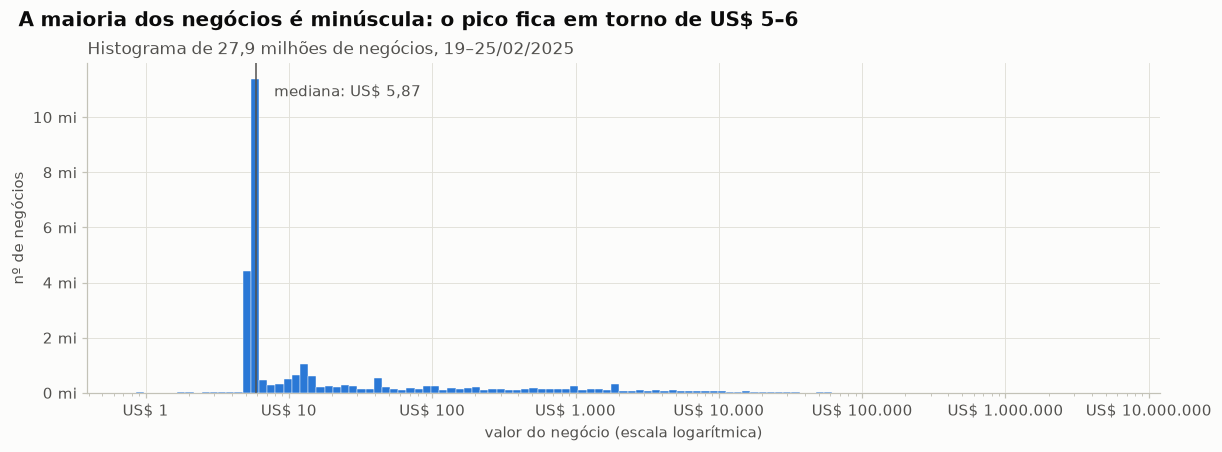

In [45]:
fig, ax = plt.subplots(figsize=(11, 4))
bins = np.logspace(np.log10(trades["notional_usd"].min()), np.log10(trades["notional_usd"].max()), 120)
ax.hist(trades["notional_usd"], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.3)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"US$ {br(v)}" if v >= 1 else f"US$ {br(v, 2)}"))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{br(v / 1e6, 0)} mi"))
median_usd = trades["notional_usd"].median()
ax.axvline(median_usd, color=INK_2, linewidth=1)
ax.annotate(f"mediana: US$ {br(median_usd, 2)}", xy=(median_usd, ax.get_ylim()[1] * 0.9),
            xytext=(12, 0), textcoords="offset points", color=INK_2, fontsize=9.5)
ax.set_xlabel("valor do negócio (escala logarítmica)")
ax.set_ylabel("nº de negócios")
ax.set_title("Histograma de 27,9 milhões de negócios, 19–25/02/2025")
headline(fig, "A maioria dos negócios é minúscula: o pico fica em torno de US$ 5–6")
plt.show()

### 7.3 Quem concentra o volume? (`groupby` por faixa de tamanho)

,negocios,volume_usd,ticket_mediano,% dos negócios,% do volume US$
size_bucket,,,,,
< US$ 100,23.123.213,"276.701.302,85","5,78","82,80","1,50"
US$ 100–1 mil,2.533.123,"1.029.093.458,39","304,45","9,07","5,57"
US$ 1–10 mil,1.871.733,"6.118.639.053,83","2.134,25","6,70","33,14"
US$ 10–100 mil,387.566,"9.436.342.874,04","17.067,95","1,39","51,12"
≥ US$ 100 mil,9.703,"1.599.664.867,26","120.057,53","0,03","8,67"


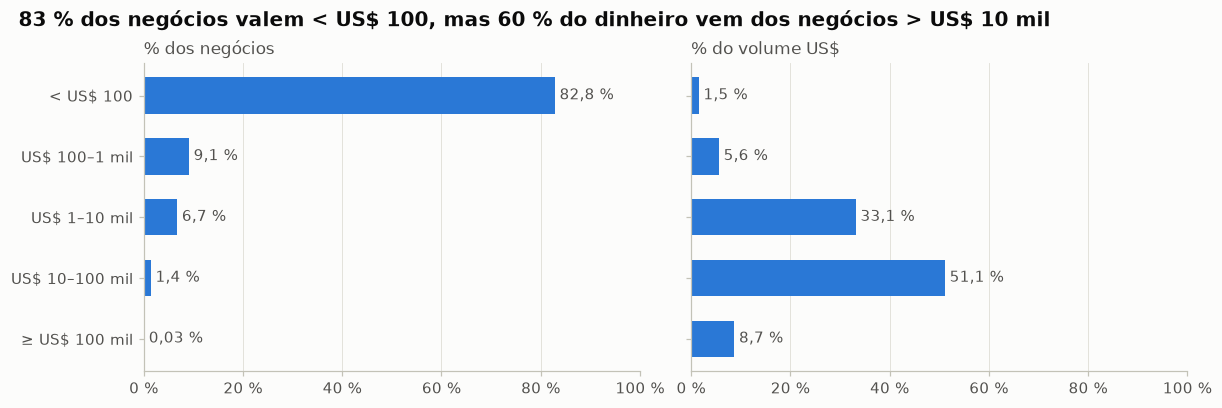

In [46]:
by_size = trades.groupby("size_bucket", observed=True).agg(
    negocios=("notional_usd", "size"), volume_usd=("notional_usd", "sum"), ticket_mediano=("notional_usd", "median"))
by_size["% dos negócios"] = by_size["negocios"] / by_size["negocios"].sum() * 100
by_size["% do volume US$"] = by_size["volume_usd"] / by_size["volume_usd"].sum() * 100
display(styled(by_size, nd=2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, col in zip(axes, ["% dos negócios", "% do volume US$"]):
    vals = by_size[col]
    ax.barh(vals.index.astype(str), vals, color=BLUE, height=0.6)
    for y, v in enumerate(vals):
        ax.text(v + 1, y, f"{br(v, 2 if v < 0.1 else 1)} %", va="center", color=INK_2, fontsize=9.5)
    ax.set_xlim(0, 100)
    ax.set_title(col)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.0f} %"))
axes[0].invert_yaxis()
headline(fig, "83 % dos negócios valem < US$ 100, mas 60 % do dinheiro vem dos negócios > US$ 10 mil")
plt.show()

Isso é **concentração extrema**. Negócios abaixo de US$ 100 são 83 % da contagem e só 1,5 % do valor. Já os negócios acima de US$ 10 mil são apenas 1,4 % da contagem e respondem por ≈ 60 % do valor negociado. Para a mesa de execução, contar negócios mede a **atividade de robôs**, enquanto somar o valor financeiro mede **liquidez de verdade**. As duas métricas contam histórias diferentes e precisam ser vistas juntas.

### 7.4 A semana em uma imagem: preço e volume

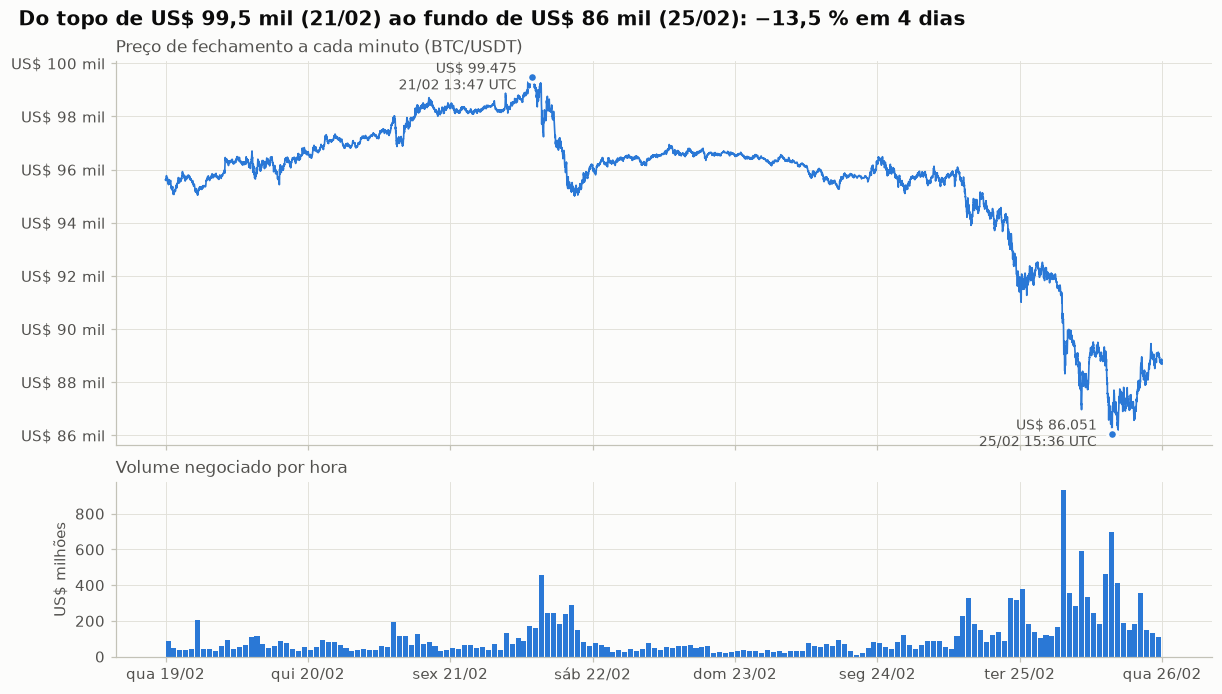

In [47]:
hourly = bars_1m.resample("1h").agg({"close": "last", "volume_usd": "sum"})
p_max_ts, p_min_ts = bars_1m["high"].idxmax(), bars_1m["low"].idxmin()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.2), sharex=True, height_ratios=[2.2, 1])
ax1.plot(bars_1m.index, bars_1m["close"], color=BLUE, linewidth=1.1)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"US$ {br(v / 1e3, 0)} mil"))
ax1.set_title("Preço de fechamento a cada minuto (BTC/USDT)")
ax1.set_ylim(bars_1m["low"].min() * 0.995, bars_1m["high"].max() * 1.006)
for ts_, val in [(p_max_ts, bars_1m["high"].max()), (p_min_ts, bars_1m["low"].min())]:
    ax1.scatter([ts_], [val], s=40, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
    ax1.annotate(f"US$ {br(val, 0)}\n{ts_:%d/%m %H:%M} UTC", xy=(ts_, val), xytext=(-10, 0),
                 textcoords="offset points", fontsize=9, color=INK_2, va="center", ha="right")

ax2.bar(hourly.index, hourly["volume_usd"] / 1e6, width=1 / 24 * 0.85, color=BLUE, align="edge")
ax2.yaxis.set_major_formatter(FMT_BR)
ax2.set_ylabel("US$ milhões")
ax2.set_title("Volume negociado por hora")
ax2.xaxis.set_major_locator(mdates.DayLocator())
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: day_label(pd.Timestamp(mdates.num2date(v)))))
headline(fig, "Do topo de US$ 99,5 mil (21/02) ao fundo de US$ 86 mil (25/02): −13,5 % em 4 dias")
plt.show()

### 7.5 Resumo diário e dias de estresse (P2)

Cada dia é classificado por uma **regra objetiva**: amplitude intradiária acima de 4 % indica **estresse**. Os demais dias são separados em *dia útil* e *fim de semana*, já que no fim de semana o mercado é naturalmente mais calmo.

In [48]:
daily = bars_1m.groupby(bars_1m.index.floor("D")).agg(
    abertura=("open", "first"), maxima=("high", "max"), minima=("low", "min"), fechamento=("close", "last"),
    volume_usd=("volume_usd", "sum"), negocios=("n_trades", "sum"),
    compra_btc=("buy_volume_btc", "sum"), volume_btc=("volume_btc", "sum"))
daily["retorno %"] = (daily["fechamento"] / daily["abertura"] - 1) * 100
daily["amplitude %"] = (daily["maxima"] / daily["minima"] - 1) * 100
daily["vol. realizada %"] = bars_1m["log_return"].pow(2).groupby(bars_1m.index.floor("D")).sum().pow(0.5) * 100
daily["% compra agressora"] = daily["compra_btc"] / daily["volume_btc"] * 100
daily["tipo"] = np.where(daily["amplitude %"] > STRESS_RANGE_THRESHOLD * 100, "estresse",
                         np.where(daily.index.day_of_week >= 5, "fim de semana", "dia útil"))
DAY_TYPE = daily["tipo"].to_numpy()          # posição 0 = 19/02, 1 = 20/02, ... (usado em 7.5 e 7.8)
daily.index = [day_label(d) for d in daily.index]
daily_view = daily.drop(columns=["compra_btc", "volume_btc"]).assign(volume_usd=lambda x: x["volume_usd"] / 1e9) \
                  .rename(columns={"volume_usd": "volume (US$ bi)"})
styled(daily_view, nd=2)

,abertura,maxima,minima,fechamento,volume (US$ bi),negocios,retorno %,amplitude %,vol. realizada %,% compra agressora,tipo
qua 19/02,"95.671,74","96.899,99","95.029,99","96.644,37","1,58",2.784.225,"1,02","1,97","1,69","43,64",dia útil
qui 20/02,"96.644,37","98.711,36","96.415,09","98.305,00","1,66",2.386.973,"1,72","2,38","1,48","48,99",dia útil
sex 21/02,"98.305,01","99.475,00","94.871,95","96.181,98","3,14",4.528.525,"-2,16","4,85","2,45","47,49",estresse
sáb 22/02,"96.181,99","96.980,00","95.770,49","96.551,01","1,09",1.506.418,"0,38","1,26","0,97","46,98",fim de semana
dom 23/02,"96.551,01","96.650,00","95.227,94","96.258,00","1,04",1.457.368,"-0,30","1,49","0,93","42,44",fim de semana
seg 24/02,"96.258,00","96.500,00","91.349,26","91.552,88","2,98",4.972.684,"-4,89","5,64","2,56","45,76",estresse
ter 25/02,"91.552,88","92.540,69","86.050,99","88.680,40","6,96",10.289.145,"-3,14","7,54","4,72","45,73",estresse


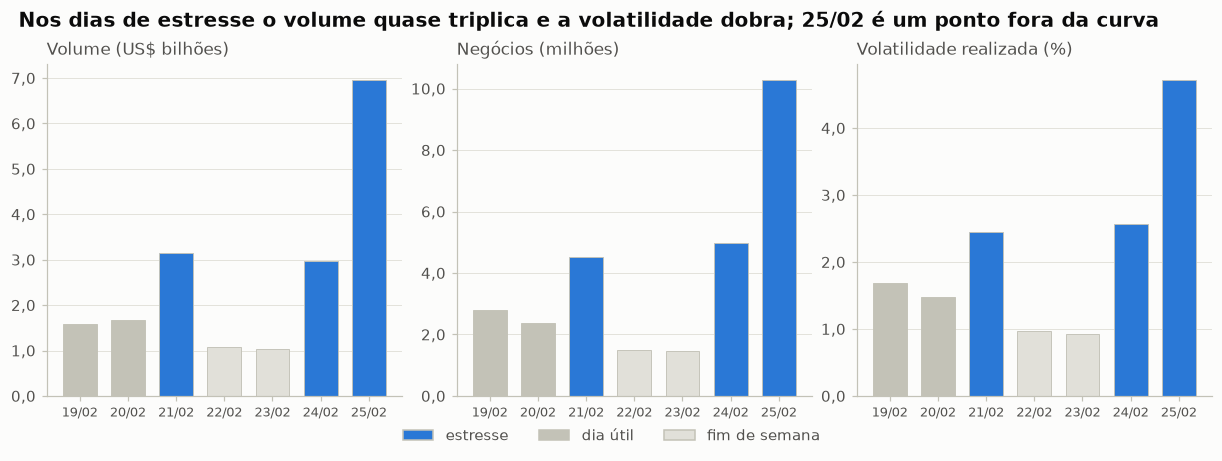

,volume (US$ bi),negocios,vol. realizada %,amplitude %
tipo,,,,
dia útil,"1,62","2.585.599,00","1,59","2,17"
estresse,"4,36","6.596.784,67","3,24","6,01"
fim de semana,"1,07","1.481.893,00","0,95","1,38"
estresse ÷ dia útil,"2,69","2,55","2,04","2,76"


In [49]:
DAY_COLORS = {"estresse": BLUE, "dia útil": AXIS, "fim de semana": GRID}
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
panels = [("volume (US$ bi)", "Volume (US$ bilhões)"), ("negocios", "Negócios (milhões)"),
          ("vol. realizada %", "Volatilidade realizada (%)")]
for ax, (col, title) in zip(axes, panels):
    values = daily_view[col] / (1e6 if col == "negocios" else 1)
    ax.bar(range(len(values)), values, color=daily_view["tipo"].map(DAY_COLORS).tolist(),
           edgecolor=AXIS, linewidth=0.6, width=0.7)
    ax.set_xticks(range(len(values)), [d.split()[1] for d in daily_view.index], fontsize=8.5)
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    ax.yaxis.set_major_formatter(FMT_BR_1)
fig.legend(handles=[Patch(facecolor=c, edgecolor=AXIS, label=k) for k, c in DAY_COLORS.items()],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08))
headline(fig, "Nos dias de estresse o volume quase triplica e a volatilidade dobra; 25/02 é um ponto fora da curva")
plt.show()

summary_by_type = daily_view.groupby("tipo")[["volume (US$ bi)", "negocios", "vol. realizada %", "amplitude %"]].mean()
summary_by_type.loc["estresse ÷ dia útil"] = summary_by_type.loc["estresse"] / summary_by_type.loc["dia útil"]
styled(summary_by_type, nd=2)

O perfil de tamanho muda nos dias de estresse? Fazemos um `groupby` em dois níveis (**tipo de dia × faixa de tamanho**) sobre as **ordens agressoras**:

In [50]:
# Índice do dia (0..6) de cada ordem -> tipo do dia
taker_orders["day_type"] = DAY_TYPE[(taker_orders["ts"] - PERIOD_START).dt.days.to_numpy()]

size_mix = (taker_orders.groupby(["day_type", "size_bucket"], observed=True)["notional_usd"].sum()
            .groupby(level=0).transform(lambda s: s / s.sum() * 100)
            .unstack("size_bucket"))
display(styled(size_mix, nd=1))

big = taker_orders[taker_orders["notional_usd"] >= 100_000]
big_daily = big.groupby(big["ts"].dt.floor("D")).agg(
    ordens=("notional_usd", "size"), volume_usd_mi=("notional_usd", lambda s: s.sum() / 1e6),
    ticket_mediano_mil=("notional_usd", lambda s: s.median() / 1e3),
    maior_ordem_mi=("notional_usd", lambda s: s.max() / 1e6))
big_daily.index = [day_label(d) for d in big_daily.index]
print("Ordens agressoras ≥ US$ 100 mil por dia:")
styled(big_daily, nd=1)

size_bucket,< US$ 100,US$ 100–1 mil,US$ 1–10 mil,US$ 10–100 mil,≥ US$ 100 mil
day_type,,,,,
dia útil,"0,5","2,5","18,1","43,0","35,9"
estresse,"0,3","2,4","15,1","41,9","40,2"
fim de semana,"0,6","3,6","17,2","40,8","37,9"


Ordens agressoras ≥ US$ 100 mil por dia:


,ordens,volume_usd_mi,ticket_mediano_mil,maior_ordem_mi
qua 19/02,2.066,"531,8","177,8","3,1"
qui 20/02,2.346,"631,6","187,6","5,1"
sex 21/02,5.100,"1.367,0","185,0","3,4"
sáb 22/02,1.514,"469,1","197,2","7,2"
dom 23/02,1.098,"338,8","191,9","4,8"
seg 24/02,4.675,"1.200,9","176,4","5,4"
ter 25/02,9.897,"2.694,2","176,1","5,4"


### 7.6 Perfil intradiário: quando há liquidez? (P1)

Usamos a **mediana** por hora: com só 7 dias, a média seria puxada pelos picos de 24 e 25/02. Horários em UTC; no horário de Brasília (BRT), subtraia 3 h.

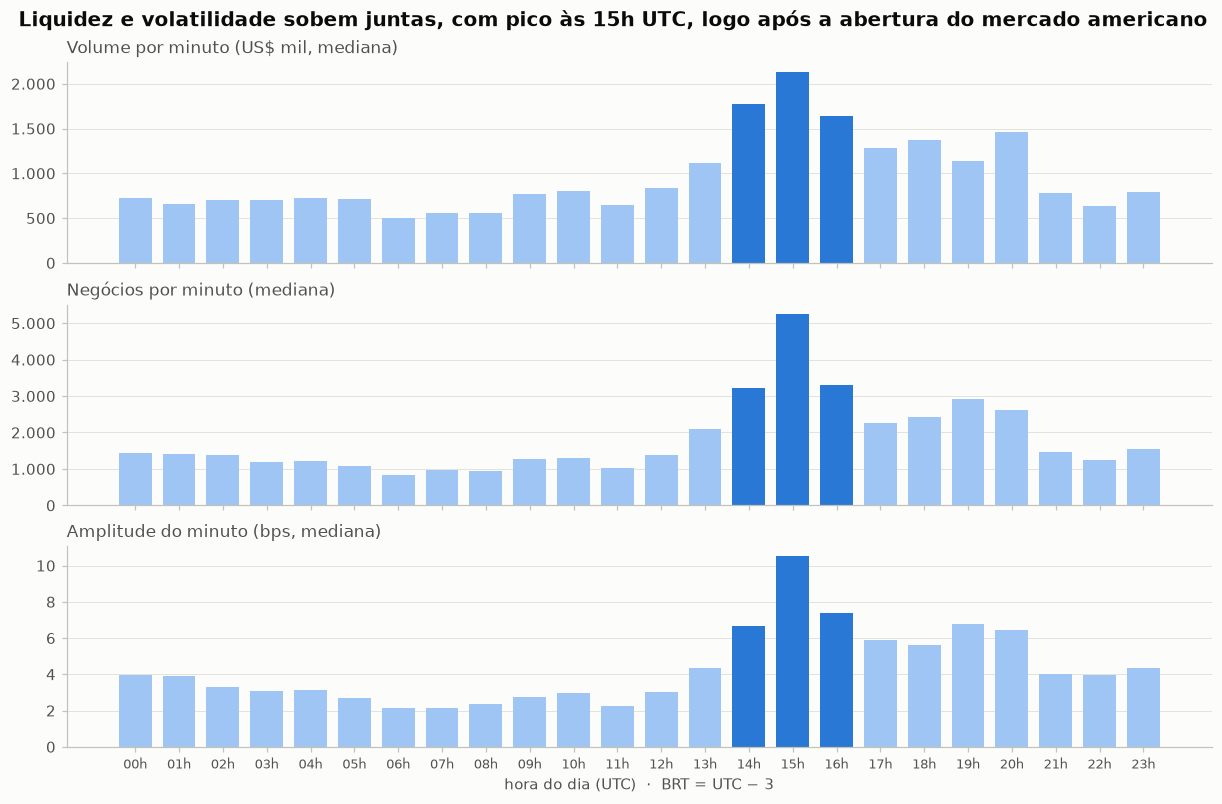

ModuleNotFoundError: No module named 'scipy'

In [51]:
by_hour = bars_1m.groupby(bars_1m.index.hour).agg(
    volume_usd_min=("volume_usd", "median"), negocios_min=("n_trades", "median"),
    abs_ret_bps=("abs_return_bps", "median"), range_bps=("range_bps", "median"))
by_hour.index.name = "hora UTC"

fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True)
panels = [("volume_usd_min", "Volume por minuto (US$ mil, mediana)", 1e3),
          ("negocios_min", "Negócios por minuto (mediana)", 1),
          ("range_bps", "Amplitude do minuto (bps, mediana)", 1)]
peak_hours = by_hour["volume_usd_min"].nlargest(3).index
for ax, (col, title, scale) in zip(axes, panels):
    colors = [BLUE if h in peak_hours else "#9ec5f4" for h in by_hour.index]
    ax.bar(by_hour.index, by_hour[col] / scale, color=colors, width=0.75)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(FMT_BR)
    ax.grid(axis="x", visible=False)
axes[-1].set_xticks(range(24), [f"{h:02d}h" for h in range(24)], fontsize=8.5)
axes[-1].set_xlabel("hora do dia (UTC)  ·  BRT = UTC − 3")
top = by_hour["volume_usd_min"].idxmax()
headline(fig, f"Liquidez e volatilidade sobem juntas, com pico às {top:02d}h UTC, logo após a abertura do mercado americano")
plt.show()

rho = by_hour["volume_usd_min"].corr(by_hour["range_bps"], method="spearman")
rho_min = bars_1m["volume_usd"].corr(bars_1m["range_bps"], method="spearman")
print(f"Correlação de Spearman volume x amplitude — entre as 24 horas: {br(rho, 2)} | minuto a minuto: {br(rho_min, 2)}")

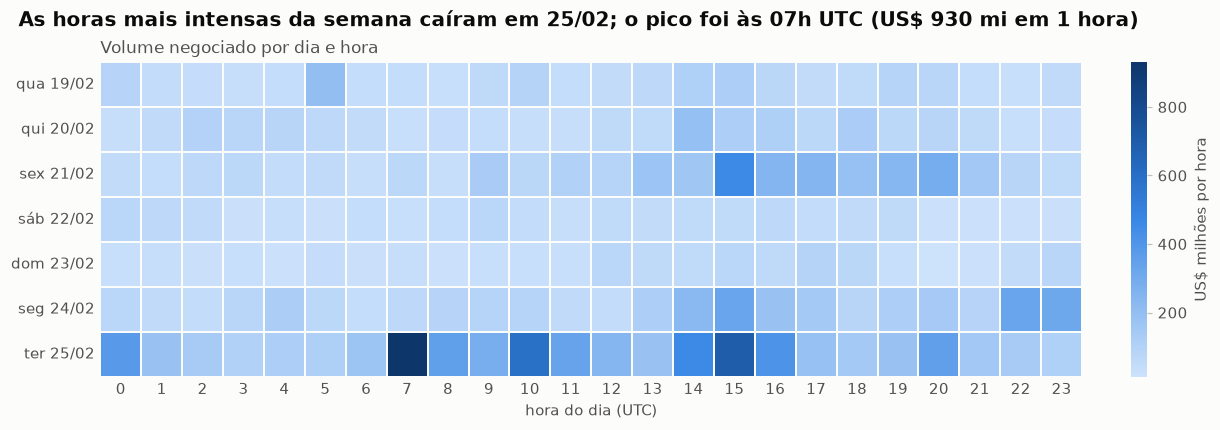

In [ ]:
heat = bars_1m.pivot_table(index=bars_1m.index.floor("D"), columns=bars_1m.index.hour,
                           values="volume_usd", aggfunc="sum") / 1e6
heat.index = [day_label(d) for d in heat.index]

fig, ax = plt.subplots(figsize=(11, 3.8))
sns.heatmap(heat, cmap=SEQ_CMAP, linewidths=1, linecolor=SURFACE, ax=ax,
            cbar_kws={"label": "US$ milhões por hora", "format": FMT_BR})
ax.set_xlabel("hora do dia (UTC)")
ax.set_ylabel("")
ax.set_title("Volume negociado por dia e hora")
ax.tick_params(length=0)
ax.grid(False)
peak_day, peak_hour = heat.stack().idxmax()
headline(fig, f"As horas mais intensas da semana caíram em 25/02; o pico foi às {peak_hour:02d}h UTC "
              f"(US$ {br(heat.loc[peak_day, peak_hour], 0)} mi em 1 hora)")
plt.show()

### 7.7 Retornos: caudas pesadas

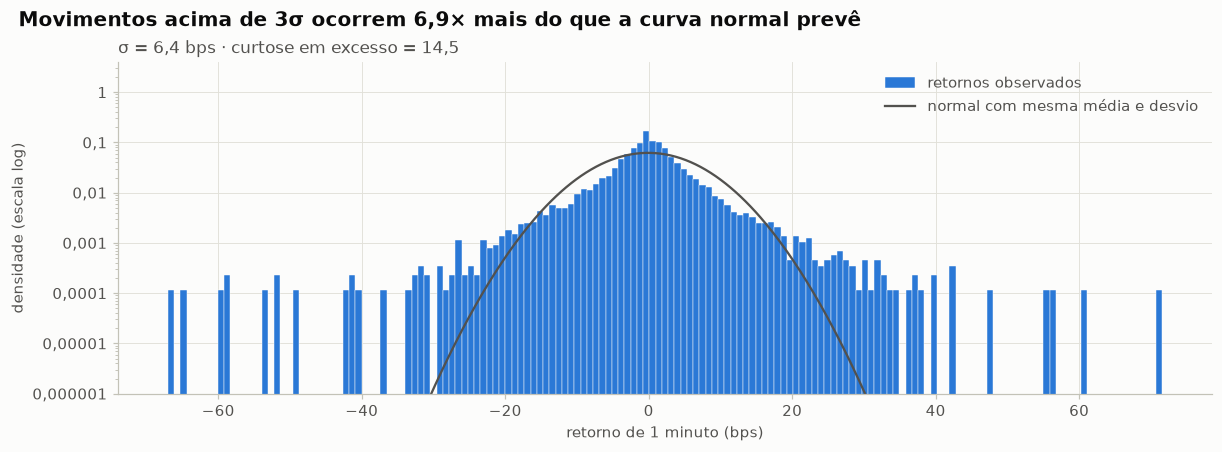

Minutos além de 3σ: 1,87 % (normal prevê 0,27 %)


In [ ]:
r_bps = bars_1m["log_return"].dropna() * 1e4
mu, sigma = r_bps.mean(), r_bps.std()
beyond_3sd = (np.abs(r_bps - mu) > 3 * sigma).mean()

fig, ax = plt.subplots(figsize=(11, 4))
edges = np.linspace(r_bps.min(), r_bps.max(), 160)
ax.hist(r_bps, bins=edges, density=True, color=BLUE, edgecolor=SURFACE, linewidth=0.3, label="retornos observados")
xs = np.linspace(r_bps.min(), r_bps.max(), 600)
ax.plot(xs, np.exp(-0.5 * ((xs - mu) / sigma) ** 2) / (sigma * np.sqrt(2 * np.pi)),
        color=INK_2, linewidth=1.5, label="normal com mesma média e desvio")
ax.set_yscale("log")
ax.set_ylim(1e-6, None)
log_axis(ax.yaxis)
ax.set_xlabel("retorno de 1 minuto (bps)")
ax.set_ylabel("densidade (escala log)")
ax.legend(loc="upper right")
ax.set_title(f"σ = {br(sigma, 1)} bps · curtose em excesso = {br(r_bps.kurt(), 1)}")
headline(fig, f"Movimentos acima de 3σ ocorrem {br(beyond_3sd / 0.0027, 1)}× mais do que a curva normal prevê")
plt.show()
print(f"Minutos além de 3σ: {br_pct(beyond_3sd, 2)} (normal prevê 0,27 %)")

### 7.8 Pressão compradora × vendedora e preço (P3)

O **Order Flow Imbalance** (OFI) de um minuto é `(volume comprador − volume vendedor) / volume total`. Vale +1 se todos os agressores compraram e −1 se todos venderam.

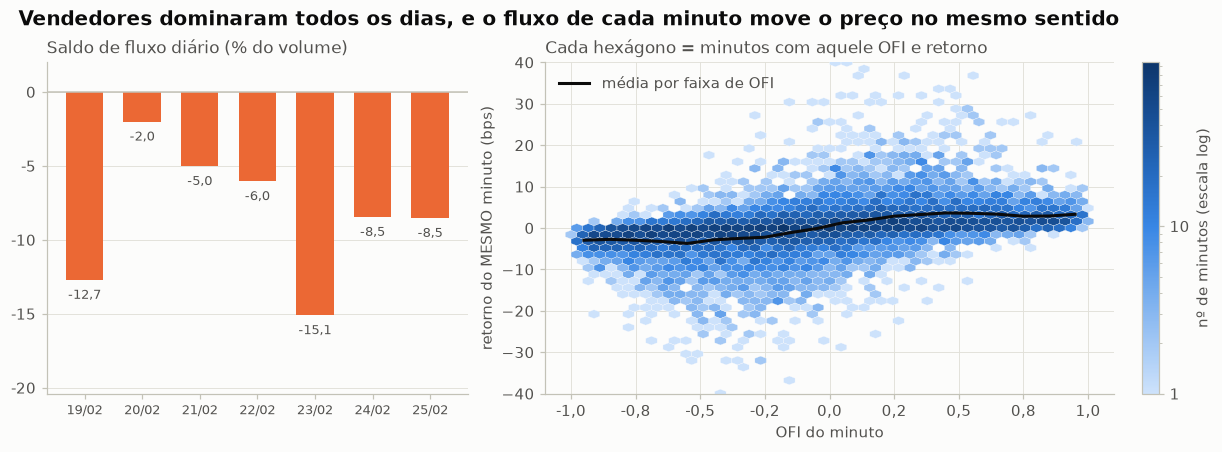

In [ ]:
net_flow = (daily["compra_btc"] * 2 - daily["volume_btc"]) / daily["volume_btc"] * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4), width_ratios=[1, 1.35])
ax = axes[0]
ax.bar(range(len(net_flow)), net_flow, color=[BLUE if v > 0 else ORANGE for v in net_flow], width=0.65)
ax.axhline(0, color=AXIS, linewidth=1)
ax.set_xticks(range(len(net_flow)), [d.split()[1] for d in net_flow.index], fontsize=8.5)
for x, v in enumerate(net_flow):
    ax.text(x, v - 0.6, f"{br(v, 1)}", ha="center", va="top", fontsize=8.5, color=INK_2)
ax.set_ylim(net_flow.min() * 1.35, 2)
ax.yaxis.set_major_locator(mticker.MultipleLocator(5))
ax.yaxis.set_major_formatter(FMT_BR)
ax.set_title("Saldo de fluxo diário (% do volume)")
ax.grid(axis="x", visible=False)

ax = axes[1]
sample = bars_1m.dropna(subset=["log_return"])
hb = ax.hexbin(sample["ofi"], sample["log_return"] * 1e4, gridsize=45, cmap=SEQ_CMAP, mincnt=1, bins="log",
               extent=(-1, 1, -40, 40), linewidths=0.2, edgecolors=SURFACE)
binned = sample.groupby(pd.cut(sample["ofi"], np.linspace(-1, 1, 21)), observed=True)["log_return"].mean() * 1e4
ax.plot([iv.mid for iv in binned.index], binned.values, color=INK, linewidth=2, label="média por faixa de OFI")
ax.set_ylim(-40, 40)
ax.set_xlabel("OFI do minuto")
ax.set_ylabel("retorno do MESMO minuto (bps)")
ax.legend(loc="upper left")
ax.set_title("Cada hexágono = minutos com aquele OFI e retorno")
ax.xaxis.set_major_formatter(FMT_BR_1)
cbar = fig.colorbar(hb, ax=ax, label="nº de minutos (escala log)")
log_axis(cbar.ax.yaxis)
headline(fig, "Vendedores dominaram todos os dias, e o fluxo de cada minuto move o preço no mesmo sentido")
plt.show()

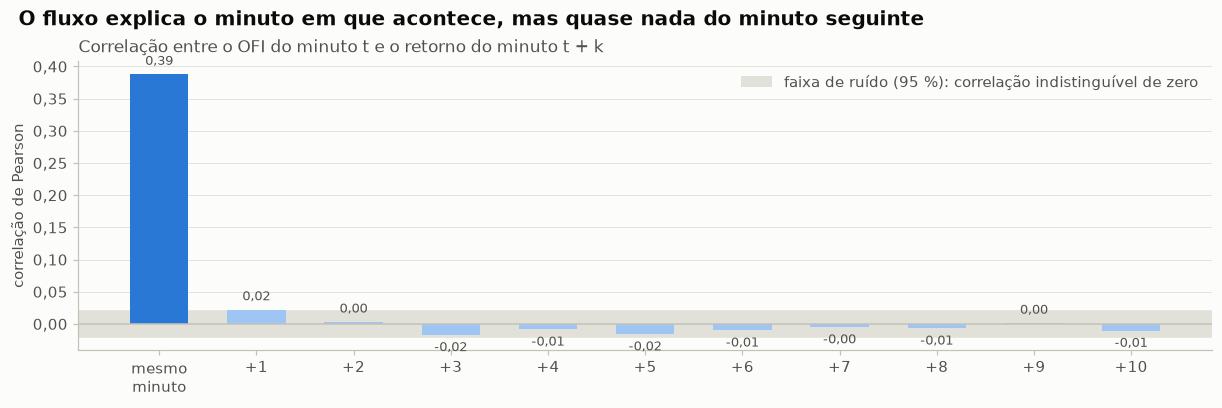

defasagem k (min),0,1,2,3,4,5,6,7,8,9,10
Pearson,"0,388","0,022","0,003","-0,017","-0,008","-0,016","-0,010","-0,005","-0,007","0,001","-0,010"
Spearman,"0,545","0,038","-0,005","-0,028","-0,017","-0,009","-0,012","-0,005","-0,010","-0,006","-0,022"


In [ ]:
lags = range(0, 11)
lag_corr = pd.DataFrame({
    "Pearson": [bars_1m["ofi"].corr(bars_1m["log_return"].shift(-k)) for k in lags],
    "Spearman": [bars_1m["ofi"].corr(bars_1m["log_return"].shift(-k), method="spearman") for k in lags],
}, index=pd.Index(lags, name="defasagem k (min)"))
signif = 1.96 / np.sqrt(bars_1m["ofi"].notna().sum())

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.bar(lag_corr.index, lag_corr["Pearson"], color=[BLUE] + ["#9ec5f4"] * (len(lag_corr) - 1), width=0.6)
ax.axhspan(-signif, signif, color=GRID, zorder=0)
ax.axhline(0, color=AXIS, linewidth=1)
ax.legend(handles=[Patch(facecolor=GRID, label="faixa de ruído (95 %): correlação indistinguível de zero")],
          loc="upper right")
ax.yaxis.set_major_formatter(FMT_BR_2)
for k, v in lag_corr["Pearson"].items():
    ax.text(k, v + (0.01 if v >= 0 else -0.01), br(v, 2), ha="center", va="bottom" if v >= 0 else "top",
            fontsize=8.5, color=INK_2)
ax.set_xticks(list(lags), ["mesmo\nminuto"] + [f"+{k}" for k in lags if k > 0])
ax.set_ylabel("correlação de Pearson")
ax.set_title("Correlação entre o OFI do minuto t e o retorno do minuto t + k")
ax.grid(axis="x", visible=False)
headline(fig, "O fluxo explica o minuto em que acontece, mas quase nada do minuto seguinte")
plt.show()
styled(lag_corr.T, nd=3)

### 7.9 Correlação entre as variáveis de 1 minuto

Usamos **Spearman** (correlação de postos), que é robusta às caudas pesadas vistas em 7.1 e 7.7.

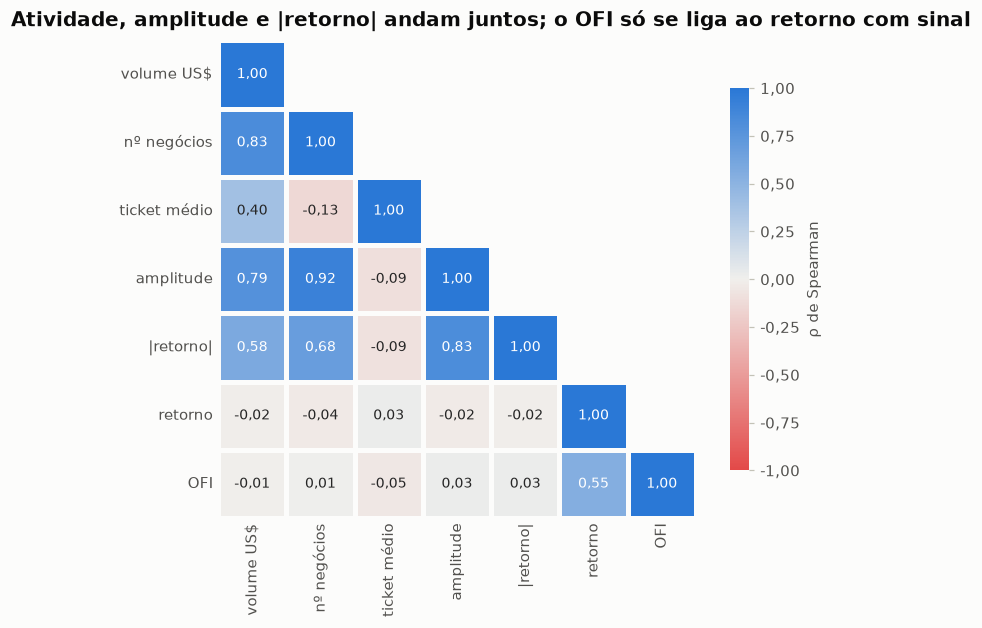

In [ ]:
corr_cols = {"volume_usd": "volume US$", "n_trades": "nº negócios", "avg_trade_usd": "ticket médio",
             "range_bps": "amplitude", "abs_return_bps": "|retorno|", "log_return": "retorno", "ofi": "OFI"}
corr = bars_1m[list(corr_cols)].rename(columns=corr_cols).corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(7.5, 5.6))
sns.heatmap(corr, mask=mask, cmap=DIV_CMAP, vmin=-1, vmax=1, center=0, square=True, linewidths=2,
            linecolor=SURFACE, annot=corr.map(lambda v: br(v, 2)).values, fmt="", annot_kws={"fontsize": 9},
            cbar_kws={"label": "ρ de Spearman", "shrink": 0.8, "format": FMT_BR_2}, ax=ax)
ax.tick_params(length=0)
ax.grid(False)
headline(fig, "Atividade, amplitude e |retorno| andam juntos; o OFI só se liga ao retorno com sinal")
plt.show()

## 8. Respostas preliminares às perguntas de negócio

In [ ]:
calm_hour = by_hour["volume_usd_min"].idxmin()
kpis = {
    "P1 · hora de maior volume (UTC)": f"{top:02d}h (mediana US$ {br(by_hour.loc[top, 'volume_usd_min'] / 1e6, 2)} mi/min)",
    "P1 · hora de menor volume (UTC)": f"{calm_hour:02d}h (mediana US$ {br(by_hour.loc[calm_hour, 'volume_usd_min'] / 1e6, 2)} mi/min)",
    "P1 · razão pico ÷ vale": f"{br(by_hour['volume_usd_min'].max() / by_hour['volume_usd_min'].min(), 1)}×",
    "P1 · Spearman volume × amplitude (horas)": br(rho, 2),
    "P2 · volume médio estresse ÷ dia útil": f"{br(summary_by_type.loc['estresse ÷ dia útil', 'volume (US$ bi)'], 1)}×",
    "P2 · volatilidade estresse ÷ dia útil": f"{br(summary_by_type.loc['estresse ÷ dia útil', 'vol. realizada %'], 1)}×",
    "P2 · % do volume em negócios ≥ US$ 10 mil": f"{br(by_size.loc[SIZE_LABELS[3:], '% do volume US$'].sum(), 1)} %",
    "P2 · % dos negócios ≥ US$ 10 mil": f"{br(by_size.loc[SIZE_LABELS[3:], '% dos negócios'].sum(), 2)} %",
    "P3 · corr. OFI × retorno (mesmo minuto)": br(lag_corr.loc[0, "Pearson"], 3),
    "P3 · corr. OFI × retorno (minuto seguinte)": br(lag_corr.loc[1, "Pearson"], 3),
    "P3 · dias com mais venda que compra": f"{int((net_flow < 0).sum())} de {len(net_flow)}",
}
pd.Series(kpis, name="valor").to_frame()

,valor
P1 · hora de maior volume (UTC),"15h (mediana US$ 2,13 mi/min)"
P1 · hora de menor volume (UTC),"06h (mediana US$ 0,51 mi/min)"
P1 · razão pico ÷ vale,"4,2×"
P1 · Spearman volume × amplitude (horas),"0,83"
P2 · volume médio estresse ÷ dia útil,"2,7×"
P2 · volatilidade estresse ÷ dia útil,"2,0×"
P2 · % do volume em negócios ≥ US$ 10 mil,"59,8 %"
P2 · % dos negócios ≥ US$ 10 mil,"1,42 %"
P3 · corr. OFI × retorno (mesmo minuto),"0,388"
P3 · corr. OFI × retorno (minuto seguinte),"0,022"


### P1 — Liquidez e janela de execução
A liquidez é **fortemente concentrada logo após a abertura do mercado americano (14h–16h UTC, 11h–13h BRT)**. Às 15h UTC o volume mediano por minuto (≈ US$ 2,1 mi) é ≈ 4× o das 06h UTC, a hora mais fraca. A volatilidade **sobe junto**: a correlação de Spearman entre volume e amplitude é de 0,83 entre as horas e de 0,79 minuto a minuto. Mesmo assim, a hora de maior volume da semana foi às 07h UTC de 25/02, durante o pânico: em estresse, a liquidez aparece fora do horário habitual. Para a mesa, isso é um *trade-off*: o horário mais líquido absorve ordens grandes com menos impacto, mas expõe a execução a movimentos mais bruscos. **Recomendação preliminar:** fatiar ordens grandes (TWAP/VWAP) dentro da janela de liquidez, evitando executar tudo de uma vez nos minutos de pico de volatilidade.

### P2 — Dias de estresse
Pela regra objetiva (amplitude > 4 %), **21, 24 e 25/02** foram dias de estresse. Neles o volume foi, em média, **≈ 2,7× o de um dia útil normal**, e a volatilidade realizada ≈ 2×. 25/02 sozinho teve 10,3 milhões de negócios (37 % da semana) e US$ 7 bi negociados. O volume é **concentrado em poucos negócios grandes**: negócios acima de US$ 10 mil são ≈ 1,4 % da contagem e ≈ 60 % do valor. Em estresse, as ordens agressoras de US$ 100 mil ou mais passam de ≈ 36 % para ≈ 40 % do volume, e só em 25/02 foram quase 10 mil delas, ≈ 4,5× um dia útil normal. **Implicação:** limites de risco e alertas devem ser calibrados por volatilidade realizada (que dobra em estresse), e no pior dia (25/02) a infraestrutura precisou processar ≈ 4× os negócios de um dia útil normal.

### P3 — Fluxo de ordens
O saldo comprador foi **negativo em todos os 7 dias** (mais venda agressora que compra), coerente com a queda de 13,5 %. No **mesmo minuto**, OFI e retorno têm correlação de Pearson ≈ **0,39** (Spearman ≈ 0,55): o fluxo "empurra" o preço. Para o **minuto seguinte**, a correlação cai para ≈ **0,02**. Ela fica pouco acima da faixa de ruído, mas explica só ≈ 0,05 % da variância do retorno (r²), o que é economicamente desprezível. Do segundo minuto em diante, nenhuma defasagem sai da faixa de ruído. **Conclusão preliminar:** o OFI de 1 minuto, sozinho e de forma linear, **não** antecipa o preço de maneira útil. Isso é consistente com um mercado eficiente nessa escala. O Checkpoint 3 vai testar horizontes mais curtos (barras de 1 s), combinações de variáveis e modelos não lineares.

### Limitações (vieses)
- **Uma semana atípica (estresse)**: não representa um período "normal". Os padrões horários precisam ser validados em mais semanas.
- **Uma corretora e um par**: outras corretoras (Coinbase, Bybit) podem ter perfis de horário diferentes.
- **Sete observações por hora do dia**: as medianas por hora são indicativas, não conclusivas.
- A reconstrução de **ordens agressoras** é aproximada (seção 6.3).

## 9. Próximos passos (Checkpoint 3)

1. **Modelagem preditiva:** prever a volatilidade do próximo intervalo (regressão) e/ou a direção do retorno (classificação) com variáveis de fluxo, volume e amplitude defasadas. Validação temporal (*walk-forward*), sem *look-ahead*.
2. **Dashboard interativo** com os indicadores de P1–P3 (filtros por dia e hora).
3. **Data Storytelling:** narrativa "da calmaria ao estresse" para a mesa de execução.
4. **Ética e LGPD:** ausência de dados pessoais; licença de uso; vieses de período e de fonte; riscos de uso de sinais de mercado.
5. **Código consolidado:** funções do ETL (`build_bars`, `fill_bar_gaps`, `validate_trades`) reutilizadas a partir dos Parquets em `data/processed/`.